# Bài 11 – Chuỗi thời gian I: phụ thuộc và mô hình ARMA

Notebook kiểm chứng **Bài 11** trên 3 bộ dữ liệu HU (Huron), LY (lynx), DR (suất sinh lợi DAX). Mỗi mục có đúng 6 tiểu mục theo đặc tả: *Nội dung lý thuyết*, *Cách triển khai*,
*Mã lệnh Python*, *Kết quả*, *Phân tích và diễn giải*, *Nhận xét*. Hai tiểu mục cuối để dạng khung `TODO(nhóm)`: mọi con số ở đây do code sinh ra,
phần diễn giải do nhóm viết.

Ký hiệu: **[D]** tính trên dữ liệu thật; **[M]** mô phỏng có điều khiển (seed 3179, `S.child_rng(...)`, kèm MCSE).
Hình lưu ở `reports/figures/`, bảng ở `reports/tables/` (tên ổn định).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys
import numpy as np, pandas as pd, scipy, statsmodels, matplotlib
import statsmodels.api as sm
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.linalg import toeplitz
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.arima_process import arma2ma, arma_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.regression.linear_model import yule_walker

from as3179ts.config import SEED
from as3179ts.data import load_processed
from as3179ts import acf_tools as A, arma_tools as R, forecast_tools as F, evaluation as E, simulation as S
from as3179ts.plotting import save_figure, show_figure, acf_bars
from as3179ts.reporting import save_table

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| statsmodels", statsmodels.__version__, "| matplotlib", matplotlib.__version__)
print("SEED =", SEED)
rng = np.random.default_rng(SEED)  # generator gốc; mỗi mục dùng S.child_rng(11, k) nên kết quả không phụ thuộc thứ tự chạy ô

DATA = {c: load_processed(c) for c in ("HU", "LY", "DR")}
NAMES = {"HU": "Hồ Huron", "LY": "Linh miêu (log10)", "DR": "Suất sinh lợi DAX"}
Y = {"HU": DATA["HU"].level_ft.to_numpy(), "LY": DATA["LY"].log10_count.to_numpy(), "DR": DATA["DR"].ret_pct.to_numpy()}
X_HU = DATA["HU"].x_centered.to_numpy(dtype=float)            # xu thế: x = năm − 1920
U_HU = sm.OLS(Y["HU"], sm.add_constant(X_HU)).fit().resid      # HU đã khử xu thế tuyến tính bằng OLS
Z = {"HU": U_HU, "LY": Y["LY"], "DR": Y["DR"]}                 # chuỗi dùng để đọc ACF/PACF (HU đã khử xu thế)


def fit_arma(code, order, **kw):
    """ARMA(p,q) bằng ML Gauss. HU có xu thế tuyến tính trong exog (như bài giảng, Mục 6)."""
    return ARIMA(Y[code], exog=X_HU if code == "HU" else None, order=order).fit(**kw)


def sig2(res):
    """σ̂² của ARIMAResults (nằm trong params, không phải thuộc tính)."""
    return float(dict(zip(res.param_names, res.params))["sigma2"])


def lb(resid, H, model_df=0):
    """(Q_LB, p-value) bằng hàm thư viện, để đối chiếu với ljung_box_manual."""
    r = acorr_ljungbox(resid, lags=[H], model_df=model_df)
    return float(r["lb_stat"].iloc[0]), float(r["lb_pvalue"].iloc[0])

Python 3.12.14 | numpy 2.5.5 | pandas 3.1.1 | scipy 1.18.1 | statsmodels 0.15.0 | matplotlib 3.11.2
SEED = 3179


## 11.1 Chuỗi thời gian, dừng và nhiễu trắng

*Bộ dữ liệu:* HU, LY, DR (cả 3)

### Nội dung lý thuyết

**Định nghĩa 1–2.** Chuỗi $\{Y_t\}$ dừng yếu nếu $\mu_t\equiv\mu$ và $\gamma(t+h,t)=\gamma(h)$ chỉ phụ thuộc độ trễ $h$.
Nhiễu trắng $WN(0,\sigma^2)$ chỉ yêu cầu không tương quan; nhiễu iid yêu cầu độc lập và cùng phân phối, nên *mạnh hơn*.
Không tương quan chưa suy ra độc lập: $r_t$ có thể không tự tương quan trong khi $r_t^2$ thì có (cụm biến động).

### Cách triển khai

Với mỗi bộ: vẽ chuỗi, trung bình trượt và phương sai trượt (cửa sổ 20 năm cho HU, LY; 250 ngày giao dịch cho DR) để
quan sát dấu hiệu không dừng. Sau đó tính $Q_{LB}(10)$ của chuỗi và của bình phương độ lệch so với trung bình. **[D]**
Với HU dùng mức nước gốc (có xu thế); phần khử xu thế xem các mục sau.

### Mã lệnh Python

In [2]:
WIN = {"HU": 20, "LY": 20, "DR": 250}
fig, axes = plt.subplots(3, 2, figsize=(11, 8))
rows = []
for i, c in enumerate(("HU", "LY", "DR")):
    s, w = pd.Series(Y[c]), WIN[c]
    rm, rv = s.rolling(w).mean(), s.rolling(w).var()
    axes[i, 0].plot(s.values, lw=0.7); axes[i, 0].plot(rm.values, color="C3")
    axes[i, 0].set_title(f"{NAMES[c]}: chuỗi và trung bình trượt (cửa sổ {w})")
    axes[i, 1].plot(rv.values, color="C2"); axes[i, 1].set_title("phương sai trượt")
    sq = Y[c] ** 2 if c == "DR" else (Y[c] - Y[c].mean()) ** 2
    rows.append({"bộ": c, "n": len(s), "cửa sổ": w, "sd(TB trượt)/sd(y)": rm.std() / s.std(),
                 "max/min phương sai trượt": rv.max() / rv.min(), "ρ̂(1)": A.sample_acf(Y[c], 1)[1],
                 "p Q_LB(10) của y": A.ljung_box_manual(Y[c], 10)[1], "p Q_LB(10) của y²": A.ljung_box_manual(sq, 10)[1]})
fig.tight_layout()
fig_path = save_figure(fig, "bai11_11_1_series")
tab = save_table(pd.DataFrame(rows).set_index("bộ"), "bai11_11_1_stationarity")

### Kết quả

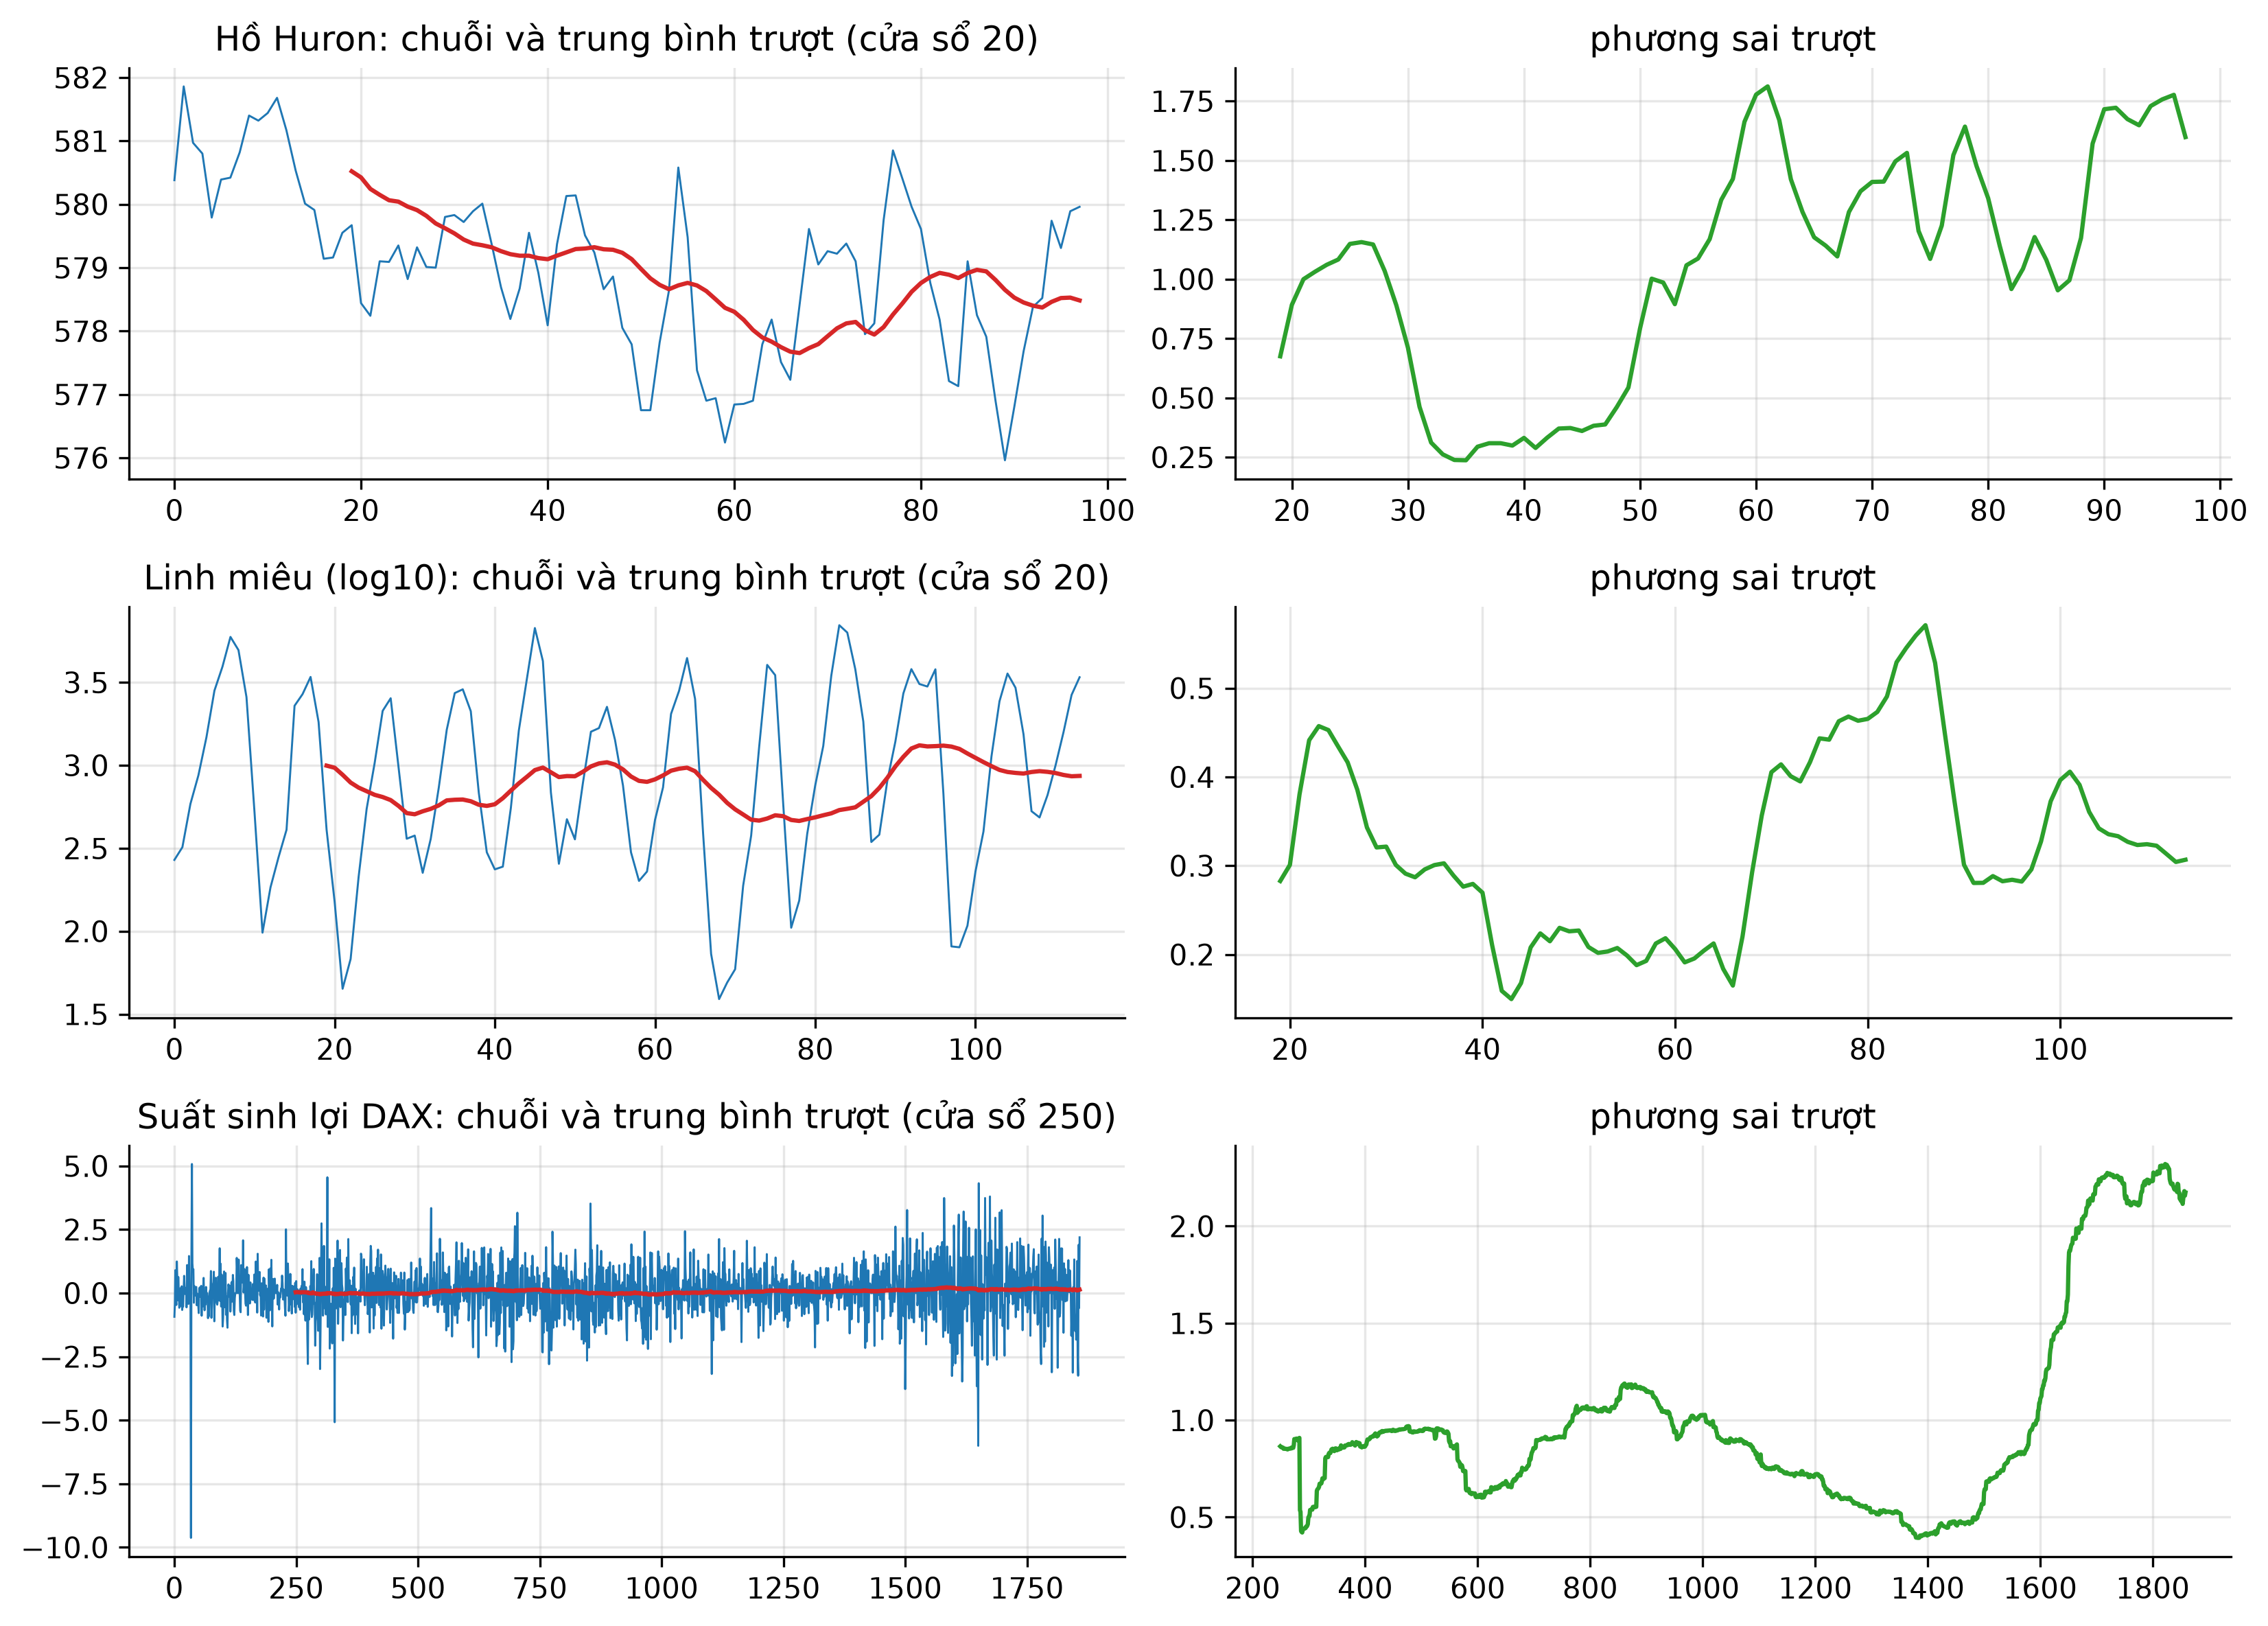

,n,cửa sổ,sd(TB trượt)/sd(y),max/min phương sai trượt,ρ̂(1),p Q_LB(10) của y,p Q_LB(10) của y²
bộ,,,,,,,
HU,98,20,0.522738,7.643185,0.831911,2.093830e-35,2.238972e-11
LY,114,20,0.231658,3.810174,0.785124,1.404911e-55,8.421816e-07
DR,1859,250,0.064883,5.900674,-0.000435,7.836711e-01,3.773008e-19


In [3]:
show_figure(fig_path)
tab

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Trung bình trượt của HU có dao động quanh một hằng số không? Điều đó nói gì về tính dừng của mức nước gốc?
- DR: $p$ của $Q_{LB}(10)$ ở $r_t$ và ở $r_t^2$ khác nhau thế nào? Điều đó phân biệt nhiễu trắng với iid ra sao?
- Phương sai trượt của DR có hằng không? Liên hệ với Định nghĩa 2(b).

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 11.2 Tính chất của hàm tự hiệp phương sai

*Bộ dữ liệu:* HU, LY, DR (cả 3)

### Nội dung lý thuyết

**Mệnh đề 1.** (a) $\gamma(0)\ge0$, $|\gamma(h)|\le\gamma(0)$ nên $|\rho(h)|\le1$; (b) $\gamma(-h)=\gamma(h)$;
(c) $\Gamma_n=[\gamma(i-j)]$ xác định không âm. **Định nghĩa 3:** $\hat\gamma(h)=\frac1n\sum_{t=1}^{n-h}(y_{t+h}-\bar y)(y_t-\bar y)$
(mẫu số $n$) bảo đảm $\hat\Gamma_n$ xác định không âm; mẫu số $n-h$ thì không còn bảo đảm (Bài tập 4(1)).

### Cách triển khai

Với mỗi bộ dựng $\hat\Gamma_n$ đầy đủ ($n\times n$) từ $\hat\gamma$ với mẫu số $n$ và với mẫu số $n-h$; tính trị riêng nhỏ nhất và
$\max_h|\hat\rho(h)|$ cho cả hai. **[D]** $\gamma(-h)=\gamma(h)$ đúng theo cách dựng ma trận Toeplitz đối xứng.

### Mã lệnh Python

In [4]:
rows, curves = [], {}
for c in ("HU", "LY", "DR"):
    y = Y[c]; n = len(y)
    g_n, g_adj = A.sample_autocov(y, n - 1, "n"), A.sample_autocov(y, n - 1, "n-h")
    curves[c] = (g_n / g_n[0], g_adj / g_adj[0])
    rows.append({"bộ": c, "n": n, "γ̂(0) ≥ 0": bool(g_n[0] >= 0),
                 "max|ρ̂(h)| (mẫu số n)": np.abs(curves[c][0]).max(), "max|ρ̂(h)| (mẫu số n−h)": np.abs(curves[c][1]).max(),
                 "trị riêng nhỏ nhất Γ̂ (n)": np.linalg.eigvalsh(toeplitz(g_n)).min(),
                 "trị riêng nhỏ nhất Γ̂ (n−h)": np.linalg.eigvalsh(toeplitz(g_adj)).min()})
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, c in zip(axes, curves):
    ax.plot(curves[c][1], lw=0.8, label="mẫu số n−h"); ax.plot(curves[c][0], lw=0.8, label="mẫu số n")
    ax.set(title=f"{c}: ρ̂(h), h = 0..n−1", xlabel="h"); ax.legend(fontsize=7)
fig.tight_layout()
fig_path = save_figure(fig, "bai11_11_2_acf_denominators")
tab = save_table(pd.DataFrame(rows).set_index("bộ"), "bai11_11_2_gamma_properties")

### Kết quả

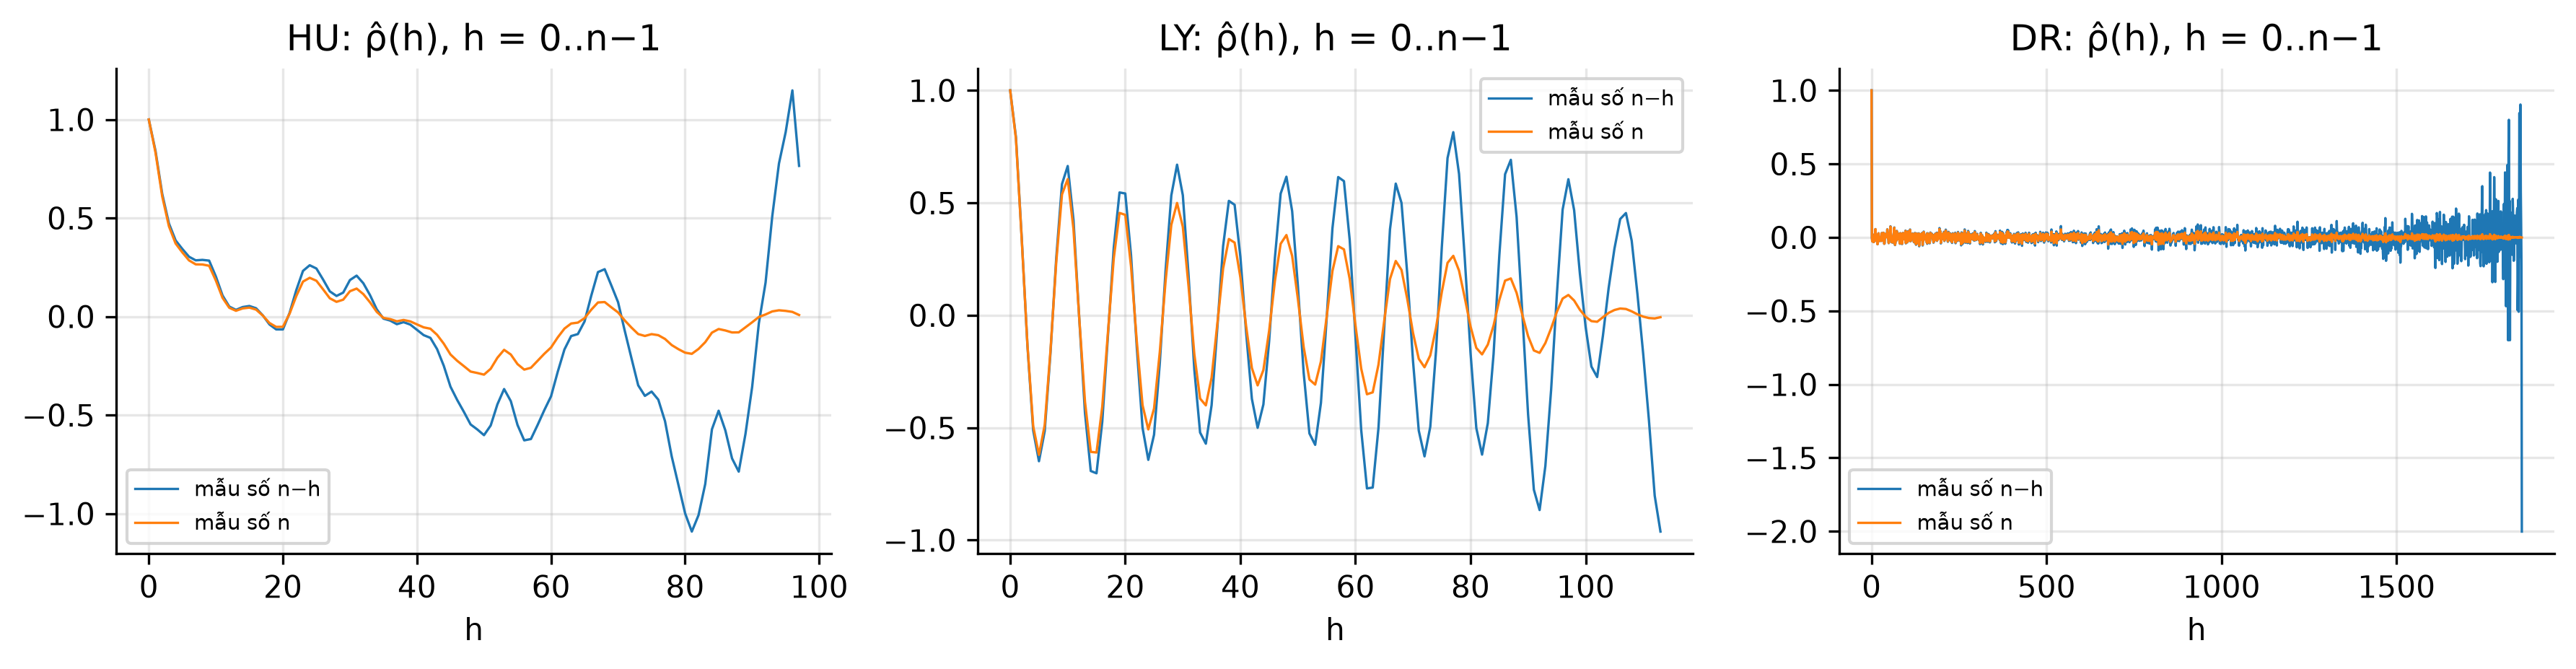

,n,γ̂(0) ≥ 0,max|ρ̂(h)| (mẫu số n),max|ρ̂(h)| (mẫu số n−h),trị riêng nhỏ nhất Γ̂ (n),trị riêng nhỏ nhất Γ̂ (n−h)
bộ,,,,,,
HU,98,True,1.0,1.147840,0.012746,-7.319497
LY,114,True,1.0,1.000000,0.000941,-0.480728
DR,1859,True,1.0,2.001371,0.058758,-4.386389


In [5]:
show_figure(fig_path)
tab

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Trị riêng nhỏ nhất của $\hat\Gamma_n$ với mẫu số $n$ có không âm không? Còn với $n-h$?
- $\max_h|\hat\rho(h)|$ với mẫu số $n-h$ có vượt 1 không, ở độ trễ nào (đồ thị)? Điều đó vi phạm mệnh đề nào?
- Vì sao ta vẫn chấp nhận độ chệch âm nhỏ của mẫu số $n$ ở độ trễ lớn?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 11.3 Trung bình mẫu khi có phụ thuộc

*Bộ dữ liệu:* HU (chính), LY, DR; mô phỏng AR(1)

### Nội dung lý thuyết

**Định lý 1.** $\operatorname{Var}\bar Y=\frac1n\sum_{|h|<n}(1-\frac{|h|}n)\gamma(h)\approx\gamma(0)\tau/n$, $\tau=1+2\sum_{h\ge1}\rho(h)$;
cỡ mẫu hiệu dụng $n_{\rm eff}=n/\tau$. Với AR(1): $\tau=(1+\phi)/(1-\phi)$. Sai số chuẩn iid $s/\sqrt n$ vì vậy quá lạc quan khi $\tau>1$.
Cùng nguyên lý: sai số chuẩn của hệ số dốc xu thế khi sai số có tự tương quan (checklist Bài 11, ý cuối).

### Cách triển khai

**[D]** Với từng bộ: SE iid $s/\sqrt n$ so với SE có xét phụ thuộc $\sqrt{\hat\gamma(0)\hat\tau/n}$, $\hat\tau$ ước lượng bằng tổng Bartlett cắt cụt ở
$K=\lfloor4(n/100)^{2/9}\rfloor$ (kiểu Newey–West) và bằng công thức AR(1) $\hat\tau=(1+\hat\rho_1)/(1-\hat\rho_1)$; kèm công thức chính xác Định lý 1(a)
thay $\hat\gamma$. Với HU, so SE hệ số dốc OLS (−0.0242) với SE khi sai số AR(2) (ML).
**[M]** AR(1), $\phi=0.6$, $n=100$, $B=2000$, seed 3179: độ phủ của KTC 95% ngây thơ và đã hiệu chỉnh $\sqrt\tau$.

### Mã lệnh Python

In [6]:
rows = []
for c in ("HU", "LY", "DR"):
    y = Y[c]; n = len(y); rho = A.sample_acf(y, n - 1); g = A.sample_autocov(y, n - 1)
    K = int(np.floor(4 * (n / 100) ** (2 / 9)))
    tau_bart = 1 + 2 * np.sum((1 - np.arange(1, K + 1) / (K + 1)) * rho[1:K + 1])
    tau_ar1 = (1 + rho[1]) / (1 - rho[1])
    var_exact = (g[0] + 2 * np.sum((1 - np.arange(1, n) / n) * g[1:])) / n
    rows.append({"bộ": c, "n": n, "K": K, "SE iid": y.std(ddof=1) / np.sqrt(n), "τ̂ (Bartlett)": tau_bart,
                 "SE hiệu chỉnh": np.sqrt(g[0] * tau_bart / n), "τ̂ (AR(1))": tau_ar1,
                 "SE (Định lý 1(a), γ̂)": np.sqrt(max(var_exact, 0)), "n_eff = n/τ̂": n / tau_bart})
tab_mean = save_table(pd.DataFrame(rows).set_index("bộ"), "bai11_11_3_mean_se")

ols = sm.OLS(Y["HU"], sm.add_constant(X_HU)).fit()
ar2 = ARIMA(Y["HU"], exog=X_HU, order=(2, 0, 0)).fit(cov_type="oim")
tab_slope = save_table(pd.DataFrame({
    "hệ số dốc": [ols.params[1], dict(zip(ar2.param_names, ar2.params))["x1"]],
    "SE": [ols.bse[1], dict(zip(ar2.param_names, ar2.bse))["x1"]],
}, index=["OLS (sai số iid)", "ML, sai số AR(2)"]).assign(t=lambda d: d["hệ số dốc"] / d["SE"]), "bai11_11_3_slope_se")

In [7]:
B, n_sim, phi = 2000, 100, 0.6
tau = (1 + phi) / (1 - phi)
simulate = lambda r: S.simulate_ar1(phi, n_sim, r)
ci_naive = lambda y: (y.mean() - 1.96 * y.std(ddof=1) / np.sqrt(n_sim), y.mean() + 1.96 * y.std(ddof=1) / np.sqrt(n_sim))
ci_corr = lambda y: (y.mean() - 1.96 * y.std(ddof=1) * np.sqrt(tau / n_sim), y.mean() + 1.96 * y.std(ddof=1) * np.sqrt(tau / n_sim))
# cùng generator con cho hai khoảng => cùng 2000 chuỗi mô phỏng
cov_naive = S.coverage_study(simulate, ci_naive, 0.0, B, S.child_rng(11, 3))
cov_corr = S.coverage_study(simulate, ci_corr, 0.0, B, S.child_rng(11, 3))
tab_cov = save_table(pd.DataFrame({"độ phủ": [cov_naive["coverage"], cov_corr["coverage"]],
                                   "MCSE": [cov_naive["mcse"], cov_corr["mcse"]], "danh nghĩa": [0.95, 0.95]},
                                  index=["ngây thơ  ȳ ± 1.96 s/√n", f"hiệu chỉnh  ȳ ± 1.96 s√(τ/n), τ = {tau:g}"]), "bai11_11_3_coverage")

### Kết quả

In [8]:
display(tab_mean)
display(tab_slope)
tab_cov

,n,K,SE iid,τ̂ (Bartlett),SE hiệu chỉnh,τ̂ (AR(1)),"SE (Định lý 1(a), γ̂)",n_eff = n/τ̂
bộ,,,,,,,,
HU,98,3,0.133168,3.086929,0.232775,10.898473,0.328418,31.746760
LY,114,4,0.052300,2.361096,0.080010,8.307696,0.027538,48.282665
DR,1859,7,0.023891,0.916297,0.022863,0.999131,0.021137,2028.817615


,hệ số dốc,SE,t
OLS (sai số iid),-0.024201,0.004036,-5.996151
"ML, sai số AR(2)",-0.021573,0.008129,-2.653992


,độ phủ,MCSE,danh nghĩa
ngây thơ ȳ ± 1.96 s/√n,0.6465,0.010690,0.95
"hiệu chỉnh ȳ ± 1.96 s√(τ/n), τ = 4",0.9440,0.005141,0.95


### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- $\hat\tau$ của HU bằng bao nhiêu, $n_{\rm eff}$ nhỏ hơn $n$ bao nhiêu lần? Khớp với lý thuyết AR(1) không?
- SE hệ số dốc khi xét sai số AR(2) lớn hơn SE của OLS bao nhiêu lần, và hệ quả với kết luận 'mực nước giảm'?
- Độ phủ ngây thơ nằm quanh mức nào so với 95%; sau hiệu chỉnh $\sqrt\tau$ thì sao (xét cả MCSE)?
- Vì sao DR hầu như không đổi giữa hai SE (liên hệ $\hat\rho(h)\approx0$)?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 11.4 ACF mẫu, dải iid, Bartlett và kiểm định Ljung–Box

*Bộ dữ liệu:* HU, LY, DR (cả 3) + mô phỏng nhiễu iid

### Nội dung lý thuyết

**Định lý 2.** (a) Dưới nhiễu iid, $\sqrt n(\hat\rho(1),\dots,\hat\rho(H))\to N(0,I_H)$, dải 95% $\pm1.96/\sqrt n$ cho từng độ trễ;
(b) $Q_{LB}(H)=n(n+2)\sum_{h=1}^H\hat\rho(h)^2/(n-h)\to\chi^2_H$ (với phần dư ARMA(p,q): $\chi^2_{H-p-q}$);
(c) Bartlett: với MA(q), $h>q$: $\sqrt n\hat\rho(h)\to N(0,1+2\sum_{k\le q}\rho(k)^2)$.

### Cách triển khai

**[D]** Tự tính $\hat\rho(h)$, $h\le20$, so với `acf`; đếm số độ trễ vượt dải iid; $Q_{LB}(10)$ tự tính so với `acorr_ljungbox`
(DR: cả $r_t$ và $r_t^2$); dải Bartlett giả định MA(1) từ $\hat\rho(1)$. **[M]** nhiễu iid $N(0,1)$, $n=200$, $B=2000$: tần suất $|\hat\rho(h)|$ vượt dải
(≈ 5%), phân phối của $Q_{LB}(10)$ so với $\chi^2_{10}$.

### Mã lệnh Python

In [9]:
series = {"HU (mức nước)": Y["HU"], "LY": Y["LY"], "DR: r": Y["DR"], "DR: r²": Y["DR"] ** 2}
rows = []
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, (name, y) in zip(axes.ravel(), series.items()):
    n = len(y); r = A.sample_acf(y, 20); band = A.bartlett_band(n)
    bart = A.bartlett_band(n, r, q=1)
    acf_bars(ax, r, n, name)
    ax.axhline(bart, color="C1", ls=":", lw=0.8); ax.axhline(-bart, color="C1", ls=":", lw=0.8)
    q, p = A.ljung_box_manual(y, 10); q_ref, p_ref = lb(y, 10)
    rows.append({"chuỗi": name, "n": n, "dải iid ±": band, "dải Bartlett MA(1) ±": bart,
                 "số lag vượt dải iid (h≤20)": int((np.abs(r[1:]) > band).sum()),
                 "max|ρ̂ tay − ρ̂ thư viện|": np.abs(r - acf(y, nlags=20, fft=False)).max(),
                 "Q_LB(10) tay": q, "Q_LB(10) thư viện": q_ref, "p-value": p})
fig.tight_layout(); fig_path = save_figure(fig, "bai11_11_4_acf")
tab = save_table(pd.DataFrame(rows).set_index("chuỗi"), "bai11_11_4_acf_ljungbox")

In [10]:
rng = S.child_rng(11, 4)
B, n_sim, H = 2000, 200, 10
band = A.bartlett_band(n_sim); outside = 0; Q = np.empty(B)
for b in range(B):
    e = rng.normal(size=n_sim)
    outside += np.sum(np.abs(A.sample_acf(e, 20)[1:]) > band)
    Q[b] = A.ljung_box_manual(e, H)[0]
reject = np.mean(Q > stats.chi2.ppf(0.95, H))
tab_sim = save_table(pd.DataFrame({
    "giá trị mô phỏng": [outside / (B * 20), reject, Q.mean(), Q.var(ddof=1), stats.kstest(Q, "chi2", args=(H,)).pvalue],
    "lý thuyết": [0.05, 0.05, H, 2 * H, np.nan],
}, index=["tỷ lệ |ρ̂(h)| vượt ±1.96/√n (h=1..20)", "tỷ lệ Q_LB(10) > χ²₁₀ 95%", "trung bình Q_LB", "phương sai Q_LB",
          "p-value KS so với χ²₁₀"]), "bai11_11_4_simulation")

### Kết quả

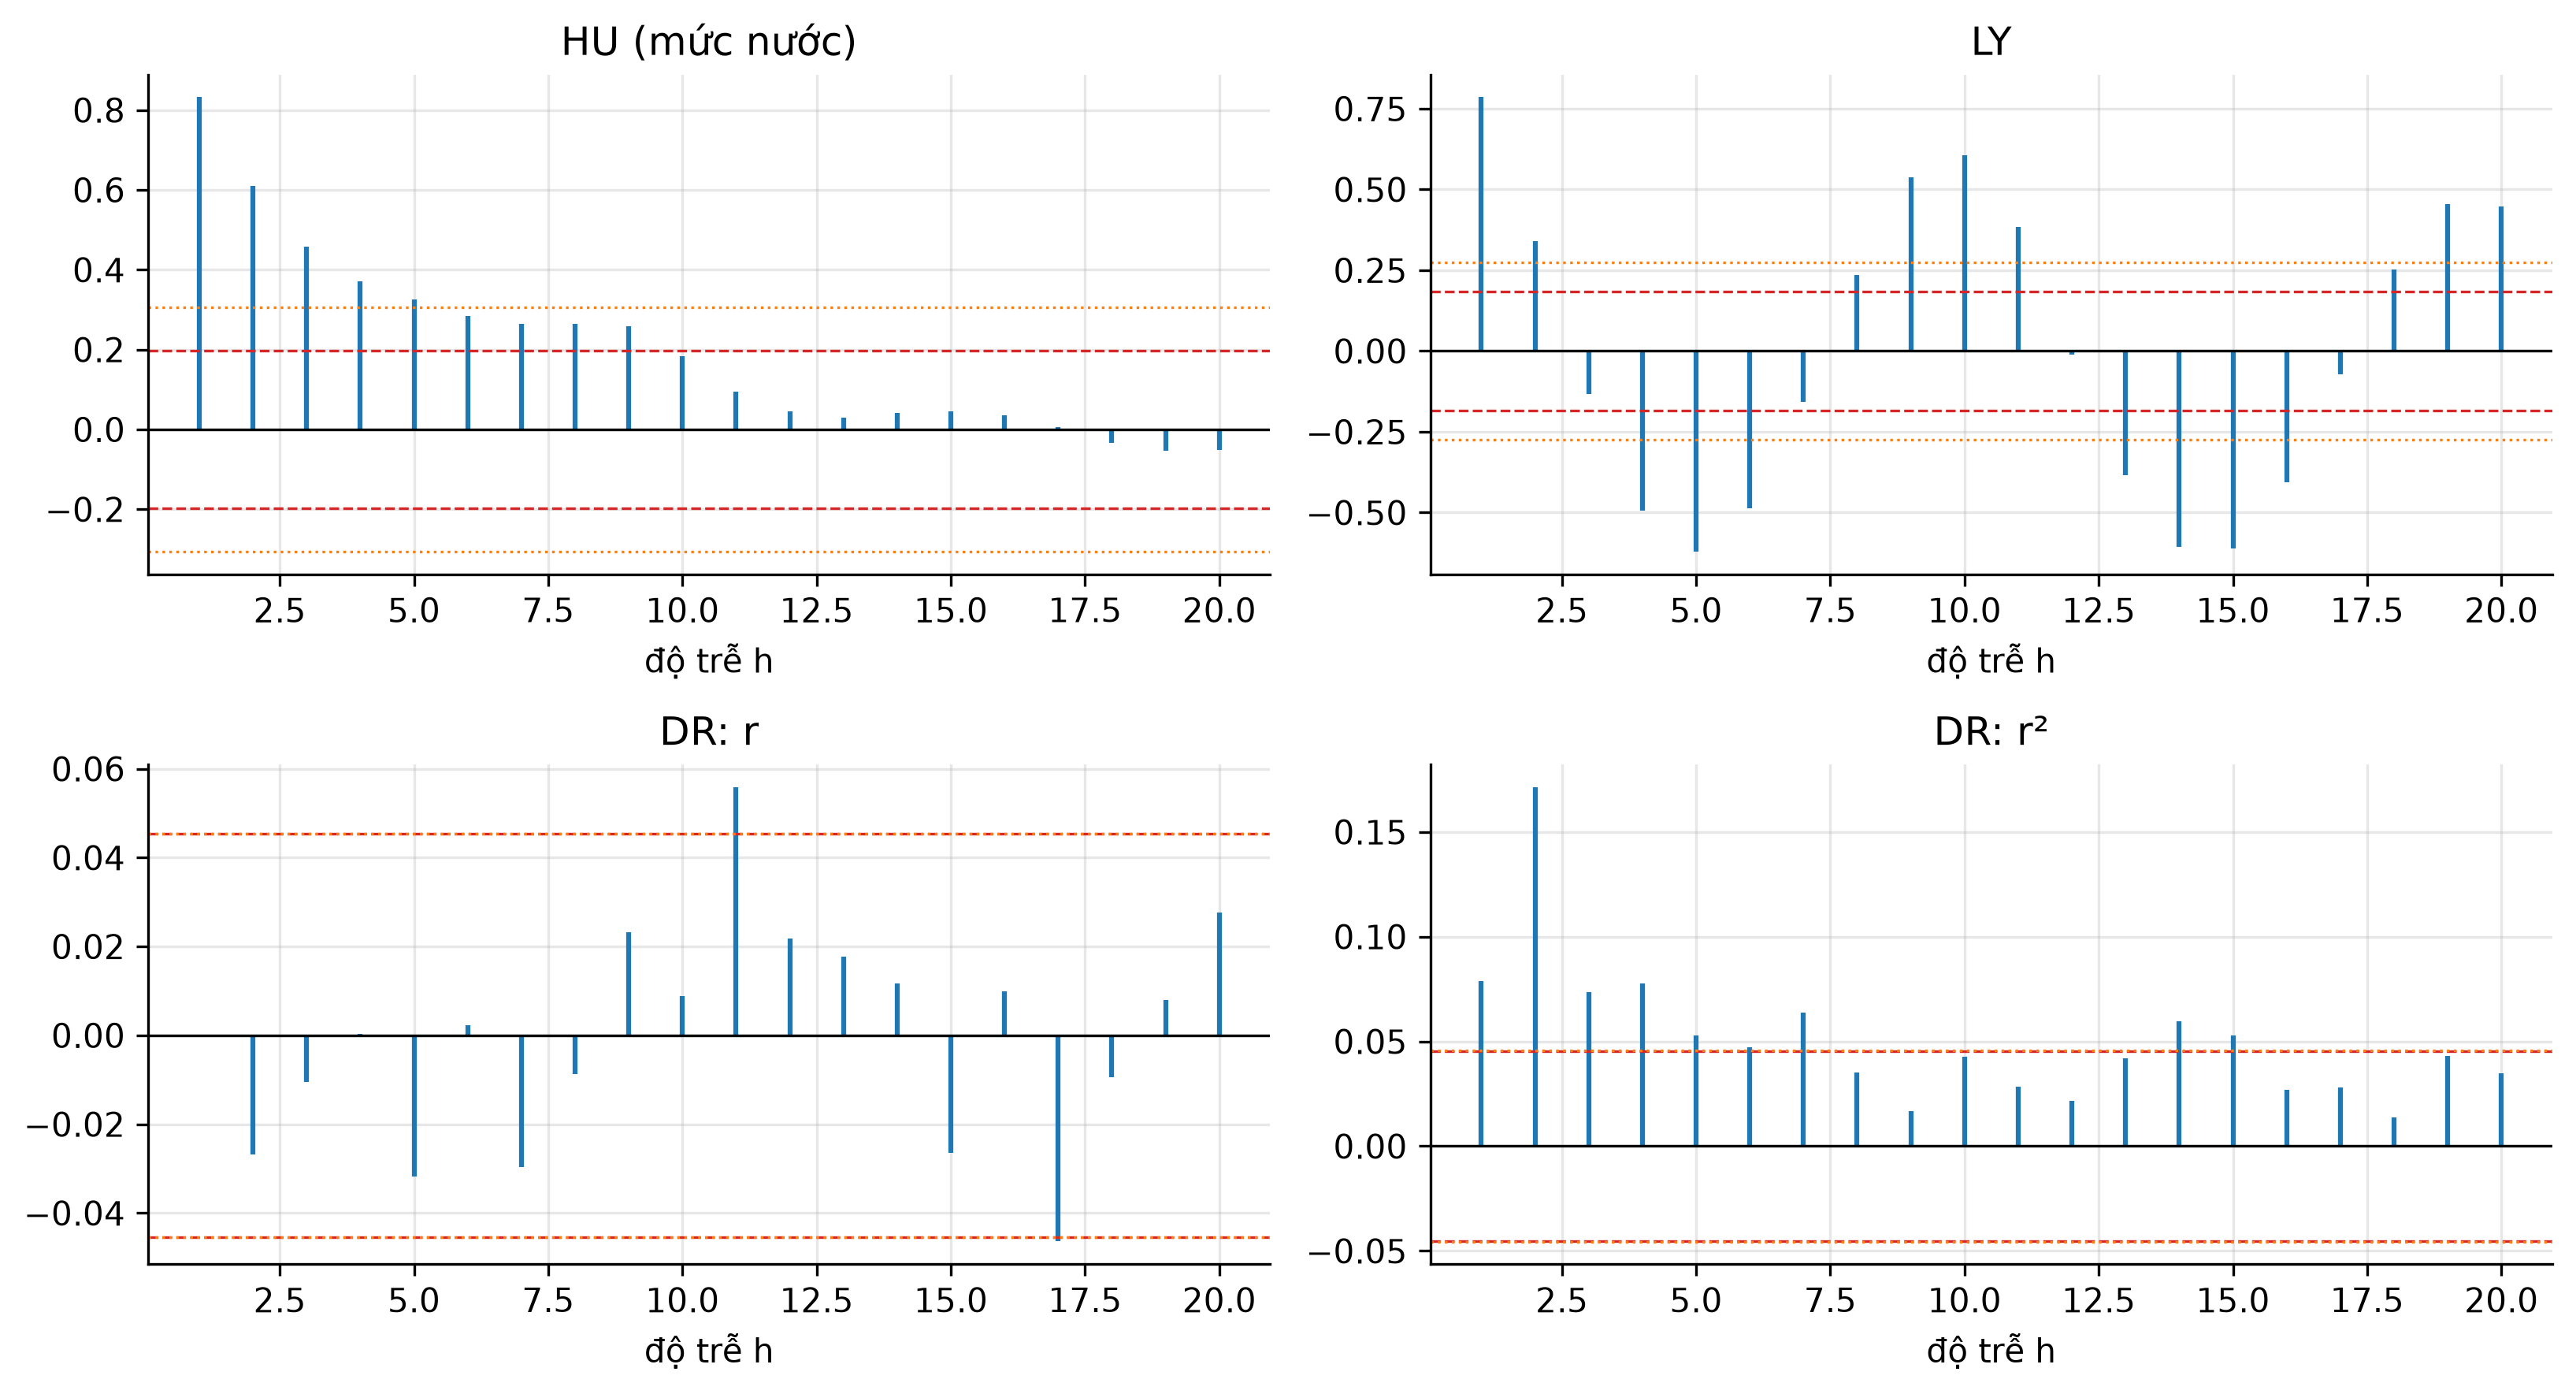

,n,dải iid ±,dải Bartlett MA(1) ±,số lag vượt dải iid (h≤20),max|ρ̂ tay − ρ̂ thư viện|,Q_LB(10) tay,Q_LB(10) thư viện,p-value
chuỗi,,,,,,,,
HU (mức nước),98,0.197990,0.305710,9,0.0,189.857006,189.857006,2.093830e-35
LY,114,0.183571,0.274304,16,0.0,286.007607,286.007607,1.404911e-55
DR: r,1859,0.045459,0.045459,2,0.0,6.365577,6.365577,7.836711e-01
DR: r²,1859,0.045459,0.045741,9,0.0,110.746179,110.746179,3.773008e-19


,giá trị mô phỏng,lý thuyết
tỷ lệ |ρ̂(h)| vượt ±1.96/√n (h=1..20),0.043550,0.05
tỷ lệ Q_LB(10) > χ²₁₀ 95%,0.061500,0.05
trung bình Q_LB,10.075966,10.00
phương sai Q_LB,22.405441,20.00
p-value KS so với χ²₁₀,0.465530,NaN


In [11]:
show_figure(fig_path)
display(tab)
tab_sim

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Với HU, LY, DR: bao nhiêu độ trễ vượt dải iid, và có thể đọc đó là 'trí nhớ' hay xu thế/dịch mức (trang 17)?
- $Q_{LB}(10)$ của $r_t$ và $r_t^2$ ở DR cho kết luận gì về 'nhiễu trắng' và 'iid'?
- Tỷ lệ vượt dải mô phỏng có ≈ 5% không? Vì sao khi xét nhiều độ trễ vài gai giả vẫn là điều bình thường?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

*Lưu ý:* dải iid không đúng cho DR vì có cụm biến động (Bài tập 4(4)).

## 11.5 Quá trình tuyến tính, toán tử lùi, trọng số ψ và ACF lý thuyết

*Bộ dữ liệu:* HU, LY (DR: giải thích không áp dụng)

### Nội dung lý thuyết

**Định nghĩa 4, Mệnh đề 2.** $\phi(B)(Y_t-\mu)=\theta(B)\varepsilon_t$ có biểu diễn nhân quả $Y_t=\mu+\sum_{j\ge0}\psi_j\varepsilon_{t-j}$ với
$\sum\psi_jz^j=\theta(z)/\phi(z)$ và $\gamma(h)=\sigma^2\sum_j\psi_j\psi_{j+h}$.

### Cách triển khai

**[D]** Khớp AR(2) bằng ML cho HU (với xu thế trong exog) và LY. Tính $\psi_j$ bằng đệ quy tay (`psi_weights`) so với `arma2ma`; tính ACF lý thuyết
$\gamma(h)=\sigma^2\sum\psi_j\psi_{j+h}$ (`theoretical_acf`) so với `arma_acf`, rồi chồng lên ACF mẫu.

### Mã lệnh Python

In [12]:
rows, fig, axes = [], *plt.subplots(1, 2, figsize=(11, 3.4))
for ax, c in zip(axes, ("HU", "LY")):
    res = fit_arma(c, (2, 0, 0)); phi = res.arparams
    psi, psi_ref = R.psi_weights(phi, [], 15), arma2ma(np.r_[1, -phi], [1], 15)
    rho, rho_ref = R.theoretical_acf(phi, [], 20), arma_acf(np.r_[1, -phi], [1], 21)
    rows.append({"bộ": c, "φ̂₁": phi[0], "φ̂₂": phi[1], "σ̂²": sig2(res), "ψ₁": psi[1], "ψ₂": psi[2], "ψ₃": psi[3],
                 "max|ψ tay − arma2ma|": np.abs(psi - psi_ref).max(), "max|ρ tay − arma_acf|": np.abs(rho - rho_ref).max()})
    acf_bars(ax, A.sample_acf(Z[c], 20), len(Z[c]), f"{NAMES[c]}: ACF mẫu (cột) và ACF lý thuyết của mô hình khớp (đường)")
    ax.plot(range(1, 21), rho[1:], "o-", color="C1", ms=3)
fig.tight_layout(); fig_path = save_figure(fig, "bai11_11_5_theoretical_acf")
tab = save_table(pd.DataFrame(rows).set_index("bộ"), "bai11_11_5_psi_acf")
print("DR: suất sinh lợi gần nhiễu trắng nên mô hình khớp có ψ = (1, 0, 0, …) và ACF lý thuyết = 0 với h ≥ 1; "
      "không có cấu trúc tuyến tính nhân quả để chồng lên ACF mẫu (xem 11.9, 11.14).")

DR: suất sinh lợi gần nhiễu trắng nên mô hình khớp có ψ = (1, 0, 0, …) và ACF lý thuyết = 0 với h ≥ 1; không có cấu trúc tuyến tính nhân quả để chồng lên ACF mẫu (xem 11.9, 11.14).


### Kết quả

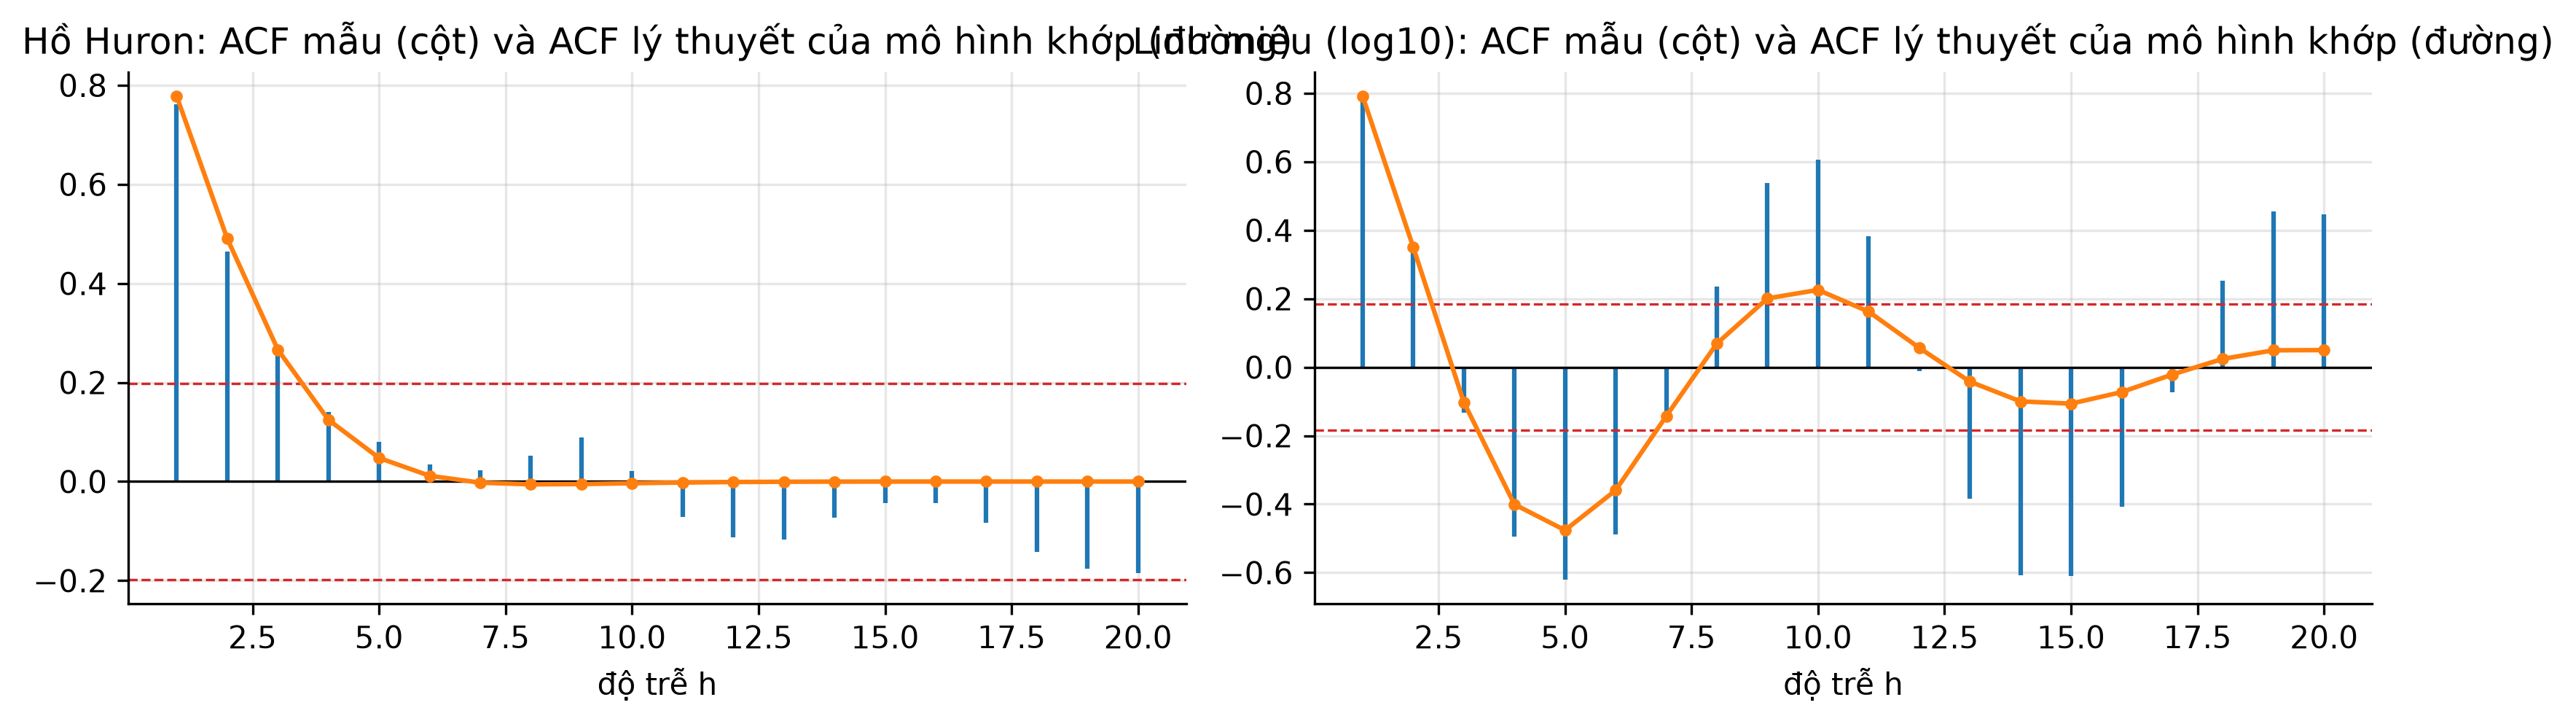

,φ̂₁,φ̂₂,σ̂²,ψ₁,ψ₂,ψ₃,max|ψ tay − arma2ma|,max|ρ tay − arma_acf|
bộ,,,,,,,,
HU,1.004816,-0.291301,0.456611,1.004816,0.718354,0.429110,0.0,1.110223e-16
LY,1.377604,-0.739870,0.051069,1.377604,1.157922,0.575909,0.0,2.220446e-16


In [13]:
show_figure(fig_path)
tab

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Các $\psi_j$ của HU, LY tắt dần thế nào, và tương ứng với dạng ACF nào (đơn điệu hay dao động)?
- ACF lý thuyết bám ACF mẫu tốt ở độ trễ nào, lệch ở đâu (liên hệ trang 32 bài giảng: AR(2) làm tắt nhanh hơn dữ liệu ở LY)?
- Sai khác giữa cài đặt tay và thư viện là bao nhiêu?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 11.6 Mô hình AR(1)

*Bộ dữ liệu:* HU (chính); LY, DR: giải thích

### Nội dung lý thuyết

**Định lý 3.** $|\phi|<1$: nghiệm dừng nhân quả duy nhất $Y_t=\mu+\sum\phi^j\varepsilon_{t-j}$; $\gamma(h)=\sigma^2\phi^{|h|}/(1-\phi^2)$,
$\rho(h)=\phi^{|h|}$; dự báo $\hat Y_{n+h}=\mu+\phi^h(Y_n-\mu)$ với MSE $\sigma^2(1-\phi^{2h})/(1-\phi^2)\to\gamma(0)$.

### Cách triển khai

**[D]** Khớp AR(1) cho HU (xu thế trong exog): so ACF mẫu của phần dư khử xu thế với $\hat\phi^h$, $\gamma(0)=\hat\sigma^2/(1-\hat\phi^2)$ với phương sai mẫu,
và MSE dự báo $h$ bước (công thức tay so với `get_forecast`). **[M]** mô phỏng AR(1) với $(\hat\phi,\hat\sigma)$, $n=98$, $B=2000$ kiểm tra $\gamma(0)$, $\rho(1)$.

### Mã lệnh Python

In [14]:
res = fit_arma("HU", (1, 0, 0)); phi, s2 = res.arparams[0], sig2(res)
g0_theory = s2 / (1 - phi ** 2)
rho_hat = A.sample_acf(U_HU, 6)
tab_acf = save_table(pd.DataFrame({"ρ̂(h) mẫu (phần dư khử xu thế)": rho_hat[1:], "φ̂^h": phi ** np.arange(1, 7)},
                                  index=pd.Index(range(1, 7), name="h")), "bai11_11_6_ar1_acf")
H = [1, 2, 5, 10]
fc = res.get_forecast(10, exog=np.arange(53, 63.0).reshape(-1, 1))
tab_fc = save_table(pd.DataFrame({
    "MSE tay σ²(1−φ^2h)/(1−φ²)": [s2 * (1 - phi ** (2 * h)) / (1 - phi ** 2) for h in H],
    "var_pred_mean (statsmodels)": [fc.var_pred_mean[h - 1] for h in H], "γ(0) giới hạn": g0_theory}, index=pd.Index(H, name="h")),
    "bai11_11_6_ar1_forecast_mse")
sim_g0, sim_r1 = [], []
rng = S.child_rng(11, 6)
for _ in range(2000):
    y = S.simulate_ar1(phi, 98, rng, sigma=np.sqrt(s2))
    sim_g0.append(A.sample_autocov(y, 0)[0]); sim_r1.append(A.sample_acf(y, 1)[1])
tab_sim = save_table(pd.DataFrame({
    "lý thuyết": [g0_theory, phi], "trung bình mô phỏng": [np.mean(sim_g0), np.mean(sim_r1)],
    "MCSE": [np.std(sim_g0, ddof=1) / np.sqrt(2000), np.std(sim_r1, ddof=1) / np.sqrt(2000)]},
    index=["γ̂(0) (mẫu số n)", "ρ̂(1)"]), "bai11_11_6_ar1_simulation")
print(f"φ̂ = {phi:.4f}, σ̂² = {s2:.4f}, γ(0) lý thuyết = {g0_theory:.4f}, phương sai mẫu phần dư khử xu thế = {A.sample_autocov(U_HU, 0)[0]:.4f}")
print("LY: AR(1) không phù hợp (chu kỳ cần AR(2), xem 11.8); DR: φ̂ ≈ 0 vì gần nhiễu trắng (xem 11.4, 11.14).")

φ̂ = 0.7835, σ̂² = 0.4965, γ(0) lý thuyết = 1.2858, phương sai mẫu phần dư khử xu thế = 1.2515
LY: AR(1) không phù hợp (chu kỳ cần AR(2), xem 11.8); DR: φ̂ ≈ 0 vì gần nhiễu trắng (xem 11.4, 11.14).


### Kết quả

In [15]:
display(tab_acf)
display(tab_fc)
tab_sim

,ρ̂(h) mẫu (phần dư khử xu thế),φ̂^h
h,,
1,0.761596,0.783475
2,0.464354,0.613832
3,0.261093,0.480922
4,0.140199,0.376790
5,0.080412,0.295206
6,0.033973,0.231286


,MSE tay σ²(1−φ^2h)/(1−φ²),var_pred_mean (statsmodels),γ(0) giới hạn
h,,,
1,0.496515,0.496515,1.285751
2,0.801292,0.801292,1.285751
5,1.173702,1.173702,1.285751
10,1.275986,1.275986,1.285751


,lý thuyết,trung bình mô phỏng,MCSE
γ̂(0) (mẫu số n),1.285751,1.176304,0.007586
ρ̂(1),0.783475,0.737542,0.001598


### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- $\hat\rho(h)$ của phần dư khử xu thế có bám $\hat\phi^h$ ở $h\ge3$ không? Nếu lệch, AR(1) thiếu điều gì (liên hệ AR(2) ở 11.12)?
- MSE dự báo tăng đến giới hạn $\gamma(0)$ nhanh cỡ nào? Bán rã của cú sốc $\log0.5/\log\hat\phi$ là bao nhiêu năm?
- $\hat\gamma(0)$ mô phỏng có thấp hơn $\gamma(0)$ không, và vì sao (mẫu số $n$, $n$ nhỏ)?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 11.7 AR(p): tính nhân quả và phương trình Yule–Walker

*Bộ dữ liệu:* LY, HU (DR: không áp dụng)

### Nội dung lý thuyết

**Định lý 4.** AR(p) có nghiệm dừng nhân quả duy nhất ⇔ mọi nghiệm của $\phi(z)=1-\phi_1z-\dots-\phi_pz^p$ có $|z|>1$.
Yule–Walker: $\Gamma_p\phi=\gamma_p$, $\sigma^2=\gamma(0)-\phi^\top\gamma_p$. **Định lý 6(a):** với mẫu số $n$, AR(p) khớp bằng YW luôn nhân quả.

### Cách triển khai

**[D]** Giải $\hat\Gamma_p\hat\phi=\hat\gamma_p$ bằng tay cho LY ($p=2$ và $p=11$) và HU đã khử xu thế ($p=2$); so với `yule_walker(method="mle")`; tính môđun các nghiệm
và kiểm tra nhân quả. DR gần nhiễu trắng nên không có cấu trúc AR đáng khớp.

### Mã lệnh Python

In [16]:
rows = []
for c, p in (("LY", 2), ("LY", 11), ("HU", 2)):
    y = Z[c]; phi, s2 = R.yule_walker_manual(y, p)
    ref, sig = yule_walker(y, order=p, method="mle")
    chk = R.causal_invertible_check(phi, [])
    resid_norm = np.linalg.norm(A.gamma_matrix(y, p) @ phi - A.sample_autocov(y, p)[1:])
    rows.append({"bộ": c, "p": p, "φ̂₁": phi[0], "φ̂₂": phi[1], "σ̂² (tay)": s2, "max|φ̂ tay − thư viện|": np.abs(phi - ref).max(),
                 "|Γ̂φ̂ − γ̂|": resid_norm, "min |z|": chk["min_ar_modulus"], "nhân quả": chk["causal"]})
tab = save_table(pd.DataFrame(rows).set_index(["bộ", "p"]), "bai11_11_7_yule_walker")
print("DR: r_t gần nhiễu trắng (11.4) nên mọi φ̂ ≈ 0 và bài toán YW không mang thông tin; bỏ qua có chủ ý.")

DR: r_t gần nhiễu trắng (11.4) nên mọi φ̂ ≈ 0 và bài toán YW không mang thông tin; bỏ qua có chủ ý.


### Kết quả

In [17]:
tab

φ̂₁       φ̂₂  σ̂² (tay)  max|φ̂ tay − thư viện|   |Γ̂φ̂ − γ̂|  \
bộ p                                                                         
LY 2   1.350438 -0.720031   0.057093            4.440892e-16  2.775558e-17   
   11  1.138709 -0.508033   0.042688            1.046385e-14  1.173473e-16   
HU 2   0.971367 -0.275436   0.485710            1.665335e-16  1.110223e-16   

        min |z|  nhân quả  
bộ p                       
LY 2   1.178486      True  
   11  1.015664      True  
HU 2   1.905415      True

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Cả ba mô hình YW có nhân quả không (min $|z|>1$)? Khớp với khẳng định của Định lý 6(a) không?
- Với LY, $p=11$: min $|z|$ gần 1 hơn $p=2$ không? Điều đó nói gì về độ dai dẳng của chu kỳ?
- Sai khác tay–thư viện cỡ bao nhiêu và vì sao có thể coi là trùng khớp?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 11.8 AR(2): tam giác nhân quả và chu kỳ

*Bộ dữ liệu:* LY (chính), HU; DR: không áp dụng

### Nội dung lý thuyết

**Mệnh đề 3.** AR(2) nhân quả ⇔ $\phi_1+\phi_2<1$, $\phi_2-\phi_1<1$, $|\phi_2|<1$ (tam giác). $\rho(1)=\phi_1/(1-\phi_2)$,
$\rho(h)=\phi_1\rho(h-1)+\phi_2\rho(h-2)$. Nghiệm phức ⇔ $\phi_1^2+4\phi_2<0$; khi đó $\rho(h)=ar^h\cos(\omega h+b)$, $r=\sqrt{-\phi_2}$,
$\cos\omega=\phi_1/(2r)$, chu kỳ tắt dần $2\pi/\omega$.

### Cách triển khai

**[D]** LY: Yule–Walker AR(2) (ví dụ mẫu trang 32), kiểm tra ba bất đẳng thức, chu kỳ từ $\omega$ và từ nghiệm đa thức ($2\pi/|\arg z|$), so với khoảng cách
giữa các đỉnh của ACF mẫu. HU: AR(2) ML (Ví dụ 3.2). Vẽ hai điểm trong tam giác nhân quả.

### Mã lệnh Python

In [18]:
pts = {}
pts["LY (Yule–Walker)"], _ = R.yule_walker_manual(Y["LY"], 2)
pts["HU (ML, có xu thế)"] = fit_arma("HU", (2, 0, 0)).arparams
rows = []
for name, (p1, p2) in pts.items():
    z = R.ar_roots(np.array([p1, p2])); complex_roots = p1 ** 2 + 4 * p2 < 0
    rows.append({"mô hình": name, "φ₁": p1, "φ₂": p2, "φ₁+φ₂<1": p1 + p2 < 1, "φ₂−φ₁<1": p2 - p1 < 1, "|φ₂|<1": abs(p2) < 1,
                 "trong tam giác": R.ar2_in_triangle(p1, p2), "nghiệm phức": complex_roots, "môđun nghiệm": abs(z[0]),
                 "chu kỳ 2π/ω": R.ar2_period(p1, p2), "chu kỳ 2π/|arg z|": 2 * np.pi / abs(np.angle(z[0])) if complex_roots else np.nan})
tab = save_table(pd.DataFrame(rows).set_index("mô hình"), "bai11_11_8_ar2_triangle")
r_ly = A.sample_acf(Y["LY"], 20)
p1, p2 = pts["LY (Yule–Walker)"]
rho_ar2 = R.theoretical_acf([p1, p2], [], 20)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
t = np.linspace(-2, 2, 200)
axes[0].fill([-2, 2, 0], [-1, -1, 1], alpha=0.15); axes[0].plot(t, -t ** 2 / 4, "C1--", label="φ₁² + 4φ₂ = 0")
for name, (a, b) in pts.items(): axes[0].plot(a, b, "o", label=name)
axes[0].set(xlabel="φ₁", ylabel="φ₂", title="Tam giác nhân quả AR(2)"); axes[0].legend(fontsize=7)
acf_bars(axes[1], r_ly, len(Y["LY"]), "LY: ρ̂(h) (cột) và ρ(h) của AR(2)-YW (đường)"); axes[1].plot(range(1, 21), rho_ar2[1:], "o-", ms=3, color="C1")
fig.tight_layout(); fig_path = save_figure(fig, "bai11_11_8_ar2_triangle")
print("Độ trễ của đỉnh ρ̂(h) trong 5 ≤ h ≤ 15 (LY):", 5 + int(np.argmax(r_ly[5:16])), "| ρ(10) lý thuyết:", round(rho_ar2[10], 3), "| ρ̂(10) mẫu:", round(r_ly[10], 3))

Độ trễ của đỉnh ρ̂(h) trong 5 ≤ h ≤ 15 (LY): 10 | ρ(10) lý thuyết: 0.198 | ρ̂(10) mẫu: 0.606


### Kết quả

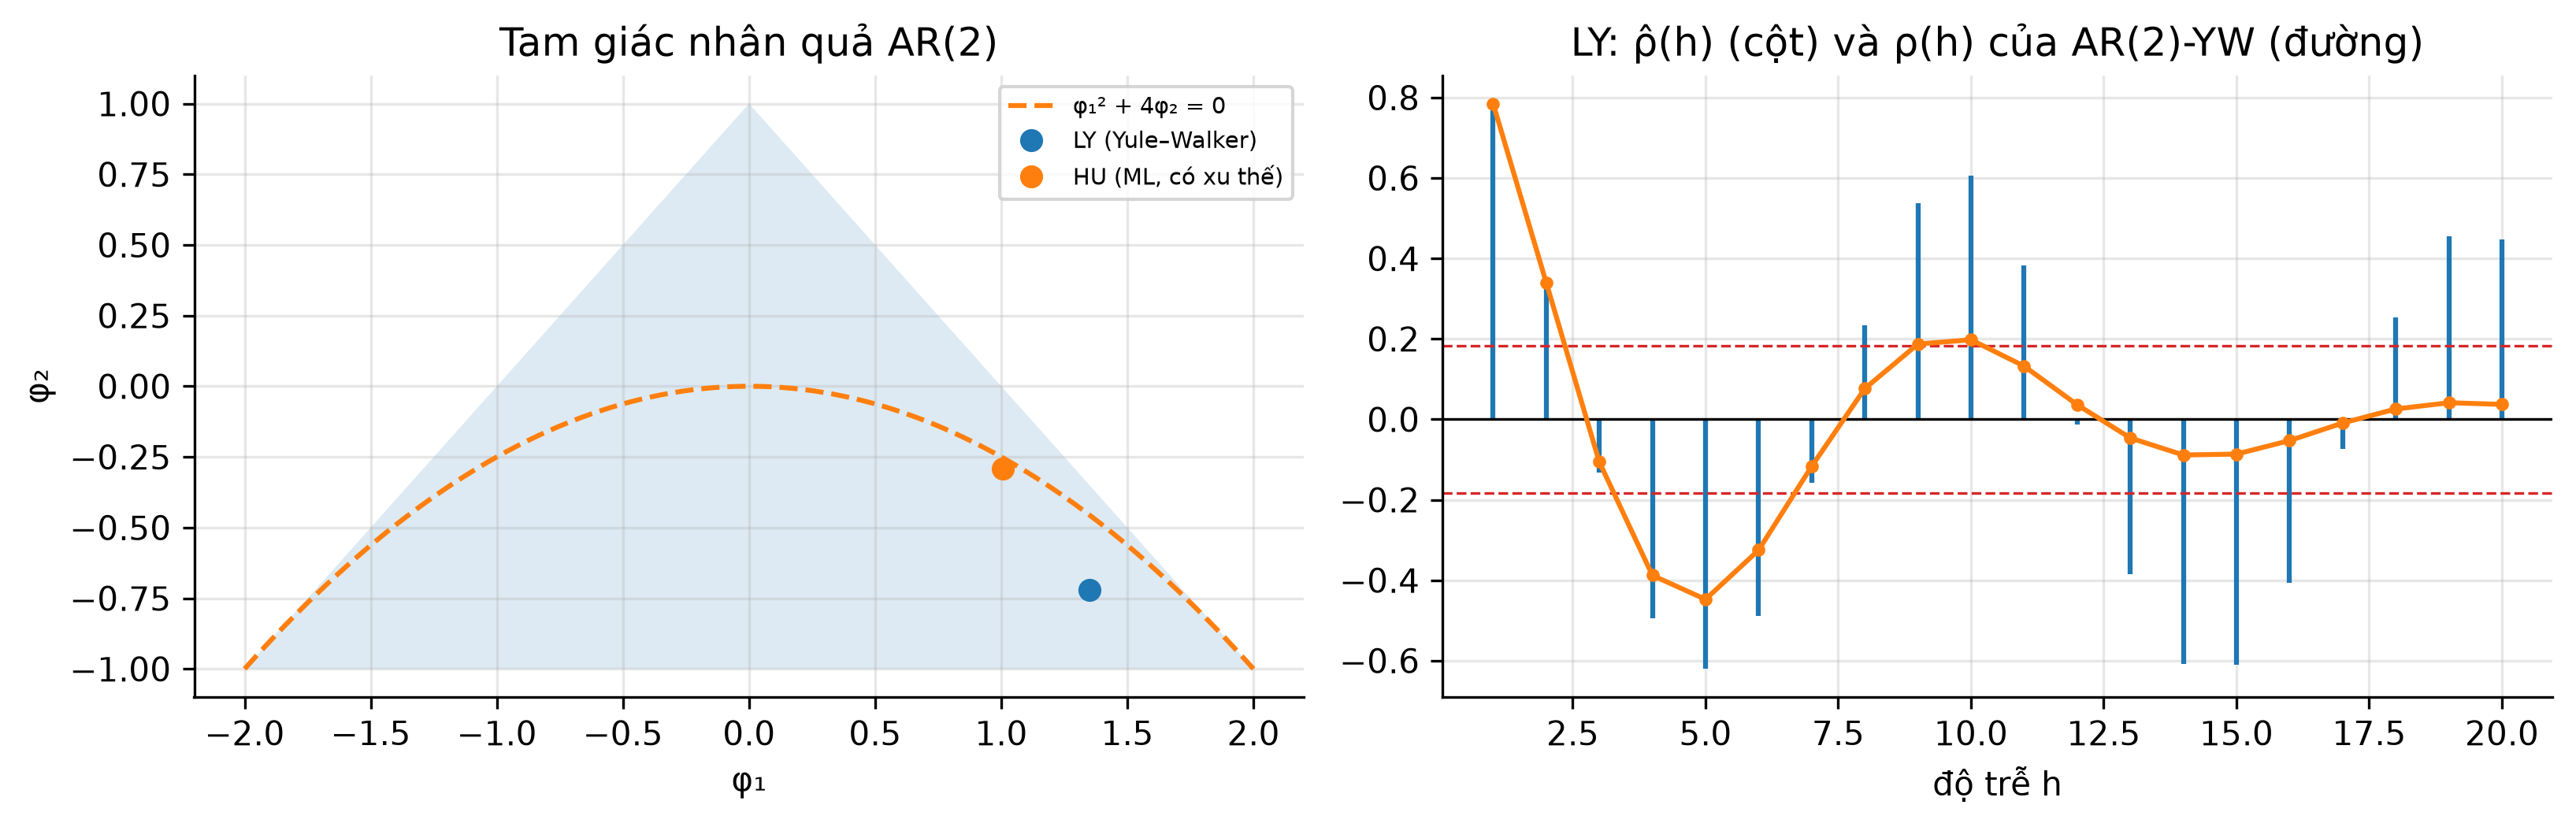

,φ₁,φ₂,φ₁+φ₂<1,φ₂−φ₁<1,|φ₂|<1,trong tam giác,nghiệm phức,môđun nghiệm,chu kỳ 2π/ω,chu kỳ 2π/|arg z|
mô hình,,,,,,,,,,
LY (Yule–Walker),1.350438,-0.720031,True,True,True,True,True,1.178486,9.657901,9.657901
"HU (ML, có xu thế)",1.004816,-0.291301,True,True,True,True,True,1.852803,16.798660,16.798660


In [19]:
show_figure(fig_path)
tab

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Điểm LY, HU có nằm trong tam giác và trong vùng nghiệm phức không? Chu kỳ tương ứng bằng bao nhiêu năm?
- Chu kỳ lý thuyết của LY (≈ 9.66 năm) có khớp với khoảng cách đỉnh của ACF mẫu không?
- AR(2) tắt nhanh hơn dữ liệu ở LY thể hiện thế nào trên đồ thị (r¹⁰ = 0.19)?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 11.9 Mô hình MA(q): ACF cắt cụt, MA(1), khả nghịch

*Bộ dữ liệu:* DR, HU (LY: giải thích) + mô phỏng MA(2)

### Nội dung lý thuyết

**Mệnh đề 4.** MA(q): $\gamma(h)=\sigma^2\sum_{j}\theta_j\theta_{j+|h|}$ bị cắt cụt sau $q$. MA(1): $\rho(1)=\theta/(1+\theta^2)$ nên $|\rho(1)|\le\frac12$;
$(\theta,\sigma^2)$ và $(1/\theta,\theta^2\sigma^2)$ cùng hàm tự hiệp phương sai; chọn mô hình khả nghịch $|\theta|<1$ (nhiễu khôi phục được từ quá khứ).

### Cách triển khai

**[D]** Khớp MA(1) cho DR, MA(1) và MA(2) cho HU (xu thế trong exog): so $\rho(1)=\hat\theta/(1+\hat\theta^2)$ với $\hat\rho(1)$ của phần dư/chuỗi, kiểm tra $|\rho(1)|\le0.5$,
và tính $\gamma(0),\gamma(1)$ của cặp $(\hat\theta,\hat\sigma^2)$, $(1/\hat\theta,\hat\theta^2\hat\sigma^2)$. **[M]** mô phỏng MA(2) với $\hat\theta$ của HU, $n=98$, $B=2000$:
ACF mẫu có cắt cụt sau độ trễ 2 không.

### Mã lệnh Python

In [20]:
dr_ma1 = fit_arma("DR", (0, 0, 1)); hu_ma1 = fit_arma("HU", (0, 0, 1)); hu_ma2 = fit_arma("HU", (0, 0, 2))
rows = []
for name, res, y in (("DR  MA(1)", dr_ma1, Y["DR"]), ("HU  MA(1)", hu_ma1, U_HU)):
    th, s2 = res.maparams[0], sig2(res)
    g_inv = R.theoretical_acvf([], [th], 1, s2); g_flip = R.theoretical_acvf([], [1 / th], 1, th ** 2 * s2)
    rows.append({"mô hình": name, "θ̂": th, "SE(θ̂)": res.bse[res.param_names.index("ma.L1")], "σ̂²": s2,
                 "ρ(1)=θ/(1+θ²)": R.ma1_ratio(th), "ρ̂(1) mẫu": A.sample_acf(y, 1)[1], "|ρ(1)| ≤ 0.5": abs(R.ma1_ratio(th)) <= 0.5,
                 "khả nghịch": abs(th) < 1, "γ(0),γ(1) của (θ,σ²)": f"{g_inv[0]:.4g}, {g_inv[1]:.4g}",
                 "γ(0),γ(1) của (1/θ,θ²σ²)": f"{g_flip[0]:.4g}, {g_flip[1]:.4g}"})
tab = save_table(pd.DataFrame(rows).set_index("mô hình"), "bai11_11_9_ma1")
print("HU MA(2): θ̂ =", hu_ma2.maparams.round(4), "| σ̂² =", round(sig2(hu_ma2), 4), "| AIC =", round(hu_ma2.aic, 2))
print("LY: ACF suy giảm dạng sóng (chu kỳ) nên MA hữu hạn không phù hợp; cấu trúc AR được dùng ở 11.7–11.8.")

HU MA(2): θ̂ = [0.956  0.4482] | σ̂² = 0.4926 | AIC = 219.75
LY: ACF suy giảm dạng sóng (chu kỳ) nên MA hữu hạn không phù hợp; cấu trúc AR được dùng ở 11.7–11.8.


D:\Projects\AS3179_Statistical-Modeling_TimeSeries\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\Projects\AS3179_Statistical-Modeling_TimeSeries\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [21]:
th = hu_ma2.maparams; s = np.sqrt(sig2(hu_ma2)); n_sim, B = 98, 2000
rho_th = R.theoretical_acf([], th, 8)
rng = S.child_rng(11, 9)
R_hat = np.array([A.sample_acf(S.simulate_arma([], th, n_sim, rng, sigma=s), 8) for _ in range(B)])
band_iid, band_bart = A.bartlett_band(n_sim), A.bartlett_band(n_sim, rho_th, q=2)
tab_sim = save_table(pd.DataFrame({
    "ρ(h) lý thuyết": rho_th[1:], "trung bình ρ̂(h)": R_hat[:, 1:].mean(0),
    "tỷ lệ vượt dải iid": (np.abs(R_hat[:, 1:]) > band_iid).mean(0),
    "tỷ lệ vượt dải Bartlett (q=2)": np.where(np.arange(1, 9) > 2, (np.abs(R_hat[:, 1:]) > band_bart).mean(0), np.nan)},
    index=pd.Index(range(1, 9), name="h")), "bai11_11_9_ma2_simulation")
fig, ax = plt.subplots(figsize=(6, 3)); ax.bar(range(1, 9), R_hat[:, 1:].mean(0), alpha=0.6, label="trung bình ρ̂(h) mô phỏng")
ax.plot(range(1, 9), rho_th[1:], "o-", color="C1", label="ρ(h) lý thuyết"); ax.legend(fontsize=8); ax.set(xlabel="h", title="MA(2): ACF cắt cụt sau độ trễ 2")
fig_path = save_figure(fig, "bai11_11_9_ma2_acf")

### Kết quả

,θ̂,SE(θ̂),σ̂²,ρ(1)=θ/(1+θ²),ρ̂(1) mẫu,|ρ(1)| ≤ 0.5,khả nghịch,"γ(0),γ(1) của (θ,σ²)","γ(0),γ(1) của (1/θ,θ²σ²)"
mô hình,,,,,,,,,
DR MA(1),-0.000495,0.018347,1.060496,-0.000495,-0.000435,True,True,"1.06, -0.000525","1.06, -0.000525"
HU MA(1),0.782195,0.071735,0.601067,0.485284,0.761596,True,True,"0.9688, 0.4702","0.9688, 0.4702"


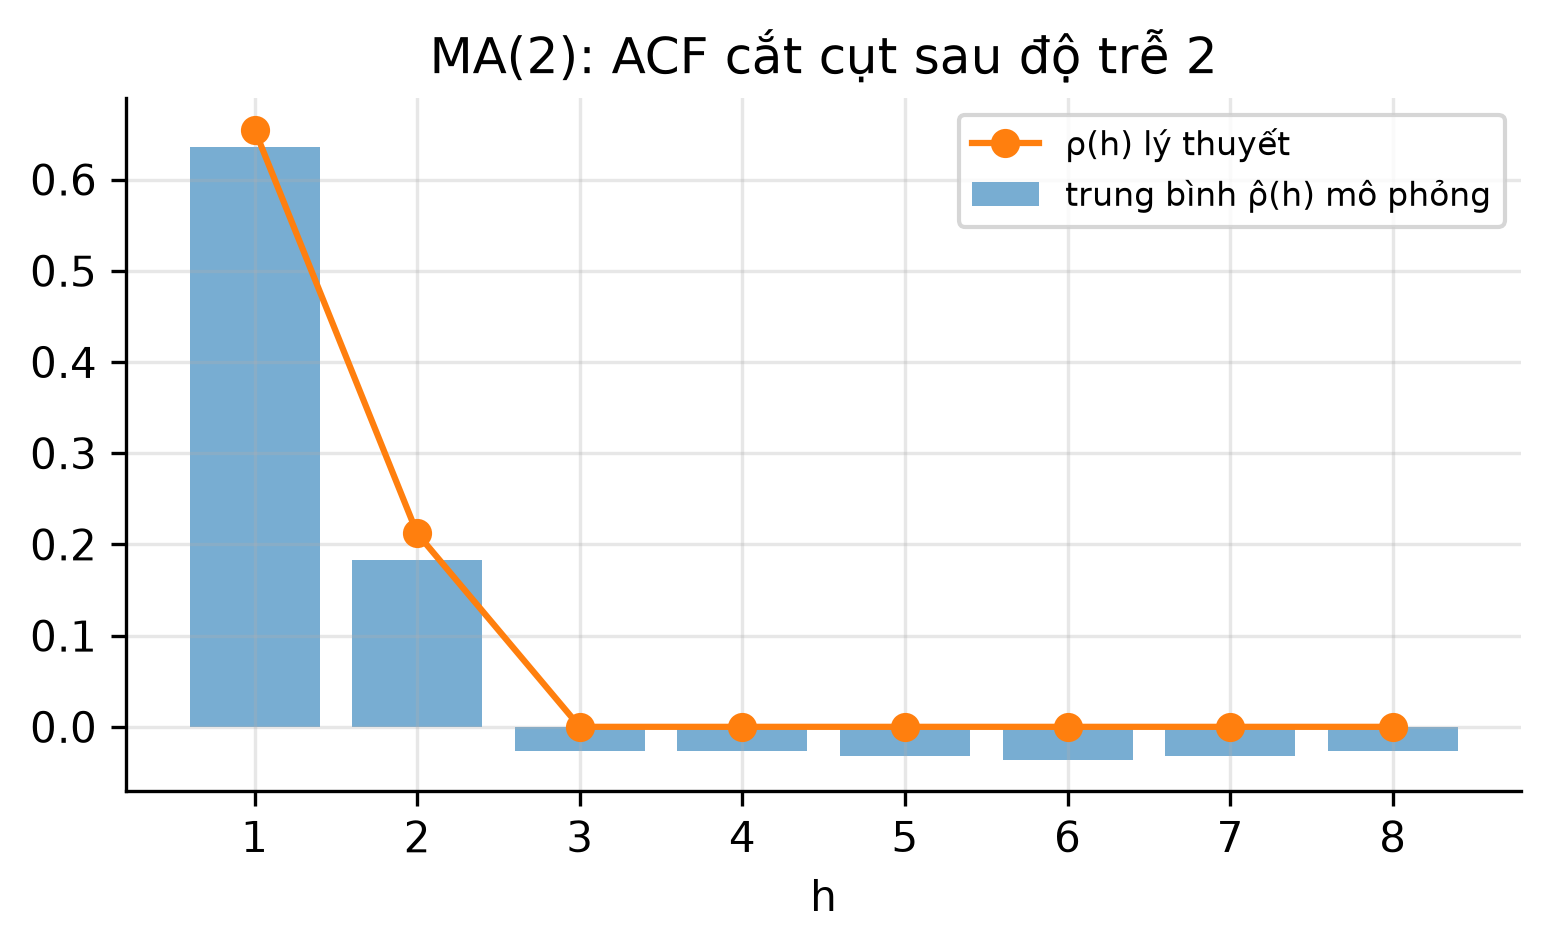

,ρ(h) lý thuyết,trung bình ρ̂(h),tỷ lệ vượt dải iid,tỷ lệ vượt dải Bartlett (q=2)
h,,,,
1,0.654663,0.635193,1.0000,NaN
2,0.211954,0.182808,0.4560,NaN
3,0.000000,-0.026623,0.1495,0.047
4,0.000000,-0.026150,0.1475,0.041
5,0.000000,-0.032421,0.1455,0.044
6,0.000000,-0.035981,0.1400,0.032
7,0.000000,-0.031988,0.1495,0.039
8,0.000000,-0.026573,0.1505,0.039


In [22]:
display(tab)
show_figure(fig_path)
tab_sim

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- θ̂ của DR có khác 0 rõ rệt (SE)? $\rho(1)$ lý thuyết so với $\hat\rho(1)$ mẫu thế nào?
- Hai mô hình $(\theta,\sigma^2)$ và $(1/\theta,\theta^2\sigma^2)$ có cùng $\gamma(0),\gamma(1)$ không? Vì sao ta chọn mô hình khả nghịch?
- Mô phỏng MA(2): $\hat\rho(h)$ với $h>2$ có ≈ 0 và tỷ lệ vượt dải iid so với dải Bartlett khác nhau ra sao?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 11.10 ARMA(p, q): nhân quả, khả nghịch, nghiệm chung

*Bộ dữ liệu:* HU, LY (DR: minh họa thừa tham số)

### Nội dung lý thuyết

**Định lý 5.** $\phi(B)(Y_t-\mu)=\theta(B)\varepsilon_t$, $\phi,\theta$ không nghiệm chung: nhân quả ⇔ $\phi(z)\ne0$ với $|z|\le1$, khả nghịch ⇔ $\theta(z)\ne0$ với $|z|\le1$;
$\psi(z)=\theta(z)/\phi(z)$. ARMA(1,1): $\psi_j=(\phi+\theta)\phi^{j-1}$, $\gamma(0)=\sigma^2\frac{1+2\phi\theta+\theta^2}{1-\phi^2}$,
$\rho(1)=\frac{(1+\phi\theta)(\phi+\theta)}{1+2\phi\theta+\theta^2}$, $\rho(h)=\phi\rho(h-1)$. Nghiệm chung bị triệt tiêu ⇒ mô hình thừa tham số, không nhận dạng được (Ví dụ 4.2).

### Cách triển khai

**[D]** Khớp ARMA(1,1) (ML) cho HU (xu thế trong exog), LY và DR; kiểm tra nghiệm AR/MA, khoảng cách nghiệm AR–MA, công thức đóng của $\psi_j$, $\gamma(0)$, $\rho(1)$ so với
cài đặt tổng quát. Minh họa thừa tham số: $Y_t=0.5Y_{t-1}+\varepsilon_t-0.5\varepsilon_{t-1}$ chính là nhiễu trắng; khớp ARMA(1,1) cho nhiễu trắng $n=200$.

### Mã lệnh Python

In [23]:
rows = []
for c in ("HU", "LY", "DR"):
    res = fit_arma(c, (1, 0, 1)); ph, th, s2 = res.arparams[0], res.maparams[0], sig2(res)
    chk = R.causal_invertible_check([ph], [th])
    psi, psi_closed = R.psi_weights([ph], [th], 6), np.r_[1.0, (ph + th) * ph ** np.arange(0, 5)]
    g0_closed = s2 * (1 + 2 * ph * th + th ** 2) / (1 - ph ** 2)
    r1_closed = (1 + ph * th) * (ph + th) / (1 + 2 * ph * th + th ** 2)
    rows.append({"bộ": c, "φ̂": ph, "θ̂": th, "σ̂²": s2, "nhân quả": chk["causal"], "khả nghịch": chk["invertible"],
                 "min|z| AR": chk["min_ar_modulus"], "min|z| MA": chk["min_ma_modulus"], "khoảng cách nghiệm AR–MA": chk["min_ar_ma_root_gap"],
                 "max|ψ tổng quát − công thức đóng|": np.abs(psi - psi_closed).max(),
                 "γ(0) công thức đóng": g0_closed, "γ(0) = σ²Σψ²": R.theoretical_acvf([ph], [th], 0, s2)[0],
                 "ρ(1) công thức đóng": r1_closed, "ρ(1) = γ(1)/γ(0)": R.theoretical_acf([ph], [th], 1)[1], "AIC": res.aic})
tab = save_table(pd.DataFrame(rows).set_index("bộ"), "bai11_11_10_arma11")

In [24]:
rng = S.child_rng(11, 10)
same = S.simulate_arma([0.5], [-0.5], 400, S.child_rng(11, 10), burn=0)
white = S.child_rng(11, 10).normal(size=400)
print("Yₜ = 0.5Yₜ₋₁ + εₜ − 0.5εₜ₋₁ trùng khít với nhiễu trắng εₜ:", np.allclose(same, white))
wn = S.simulate_arma([], [], 200, rng)
res_wn = ARIMA(wn, order=(1, 0, 1)).fit()
chk = R.causal_invertible_check(res_wn.arparams, res_wn.maparams)
tab_over = save_table(pd.DataFrame({"ước lượng": list(res_wn.params), "SE": list(res_wn.bse)}, index=res_wn.param_names)
                      .assign(**{"φ̂+θ̂": res_wn.arparams[0] + res_wn.maparams[0], "khoảng cách nghiệm AR–MA": chk["min_ar_ma_root_gap"]}),
                      "bai11_11_10_overparameterized")

Yₜ = 0.5Yₜ₋₁ + εₜ − 0.5εₜ₋₁ trùng khít với nhiễu trắng εₜ: True


### Kết quả

In [25]:
tab.T
tab_over

,ước lượng,SE,φ̂+θ̂,khoảng cách nghiệm AR–MA
const,-0.080403,0.083087,0.047004,0.657209
ar.L1,0.291966,1.363810,0.047004,0.657209
ma.L1,-0.244962,1.379067,0.047004,0.657209
sigma2,1.210749,0.133768,0.047004,0.657209


### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- HU, LY: mô hình ARMA(1,1) có nhân quả và khả nghịch không; khoảng cách nghiệm AR–MA có nhỏ (gần triệt tiêu) không?
- Công thức đóng $\psi_j$, $\gamma(0)$, $\rho(1)$ có trùng cài đặt tổng quát không?
- Với nhiễu trắng, $\hat\phi+\hat\theta$ và SE lớn nói gì về nhận dạng? DR có dấu hiệu thừa tham số tương tự không?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 11.11 Tự tương quan riêng phần (PACF)

*Bộ dữ liệu:* HU (đã khử xu thế), LY, DR (cả 3)

### Nội dung lý thuyết

**Định nghĩa 6, Mệnh đề 5.** $\alpha(h)=\phi_{hh}$ từ $\Gamma_h\phi_h=\gamma_h$; $\alpha(1)=\rho(1)$, $\alpha(2)=\frac{\rho(2)-\rho(1)^2}{1-\rho(1)^2}$; AR(p) nhân quả: $\alpha(h)=0$ với $h>p$;
MA khả nghịch: PACF suy giảm. Dải $\pm1.96/\sqrt n$ (MĐ 5(d)). Đệ quy Durbin–Levinson tính mọi $\phi_{hh}$ từ $\rho$.

### Cách triển khai

**[D]** Tính PACF mẫu bằng Durbin–Levinson tự cài, so với `pacf(method="ldb")`; kiểm tra công thức $\hat\alpha(1),\hat\alpha(2)$ theo $\hat\rho$; liệt kê độ trễ vượt dải $\pm1.96/\sqrt n$ và đề xuất bậc $p$.

### Mã lệnh Python

In [26]:
rows = []; fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, c in zip(axes, ("HU", "LY", "DR")):
    y, n = Z[c], len(Z[c]); rho = A.sample_acf(y, 20); a = A.pacf_durbin_levinson(rho, 20); band = A.bartlett_band(n)
    sig = [h for h in range(1, 21) if abs(a[h]) > band]
    rows.append({"bộ": c + (" (khử xu thế)" if c == "HU" else ""), "α̂(1) = ρ̂(1)": a[1] - rho[1],
                 "α̂(2) − (ρ̂₂−ρ̂₁²)/(1−ρ̂₁²)": a[2] - (rho[2] - rho[1] ** 2) / (1 - rho[1] ** 2),
                 "max|PACF tay − pacf()|": np.abs(a - pacf(y, nlags=20, method="ldb")).max(), "dải ±": band,
                 "độ trễ vượt dải (h≤20)": str(sig), "bậc AR gợi ý (lag cuối vượt dải ≤ 12)": max([h for h in sig if h <= 12], default=0)})
    acf_bars(ax, a, n, f"{c}: PACF α̂(h)")
fig.tight_layout(); fig_path = save_figure(fig, "bai11_11_11_pacf")
tab = save_table(pd.DataFrame(rows).set_index("bộ"), "bai11_11_11_pacf")

### Kết quả

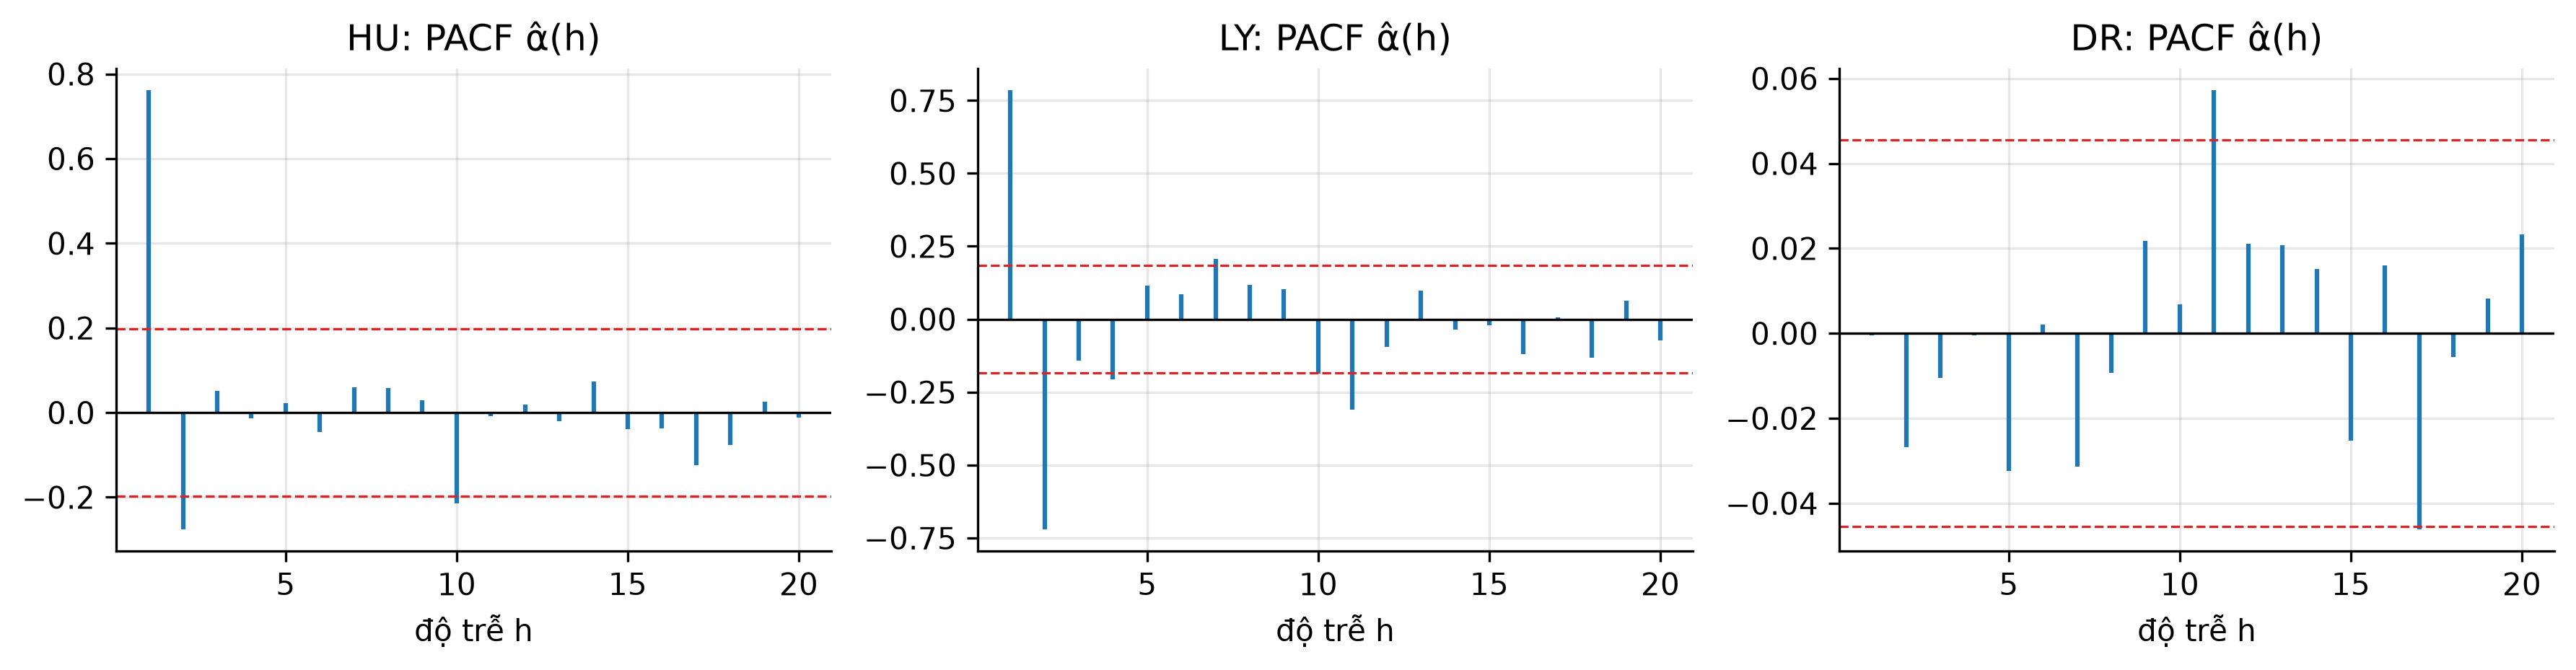

,α̂(1) = ρ̂(1),α̂(2) − (ρ̂₂−ρ̂₁²)/(1−ρ̂₁²),max|PACF tay − pacf()|,dải ±,độ trễ vượt dải (h≤20),bậc AR gợi ý (lag cuối vượt dải ≤ 12)
bộ,,,,,,
HU (khử xu thế),0.0,0.0,1.665335e-16,0.197990,"[1, 2, 10]",10
LY,0.0,0.0,2.706169e-15,0.183571,"[1, 2, 4, 7, 10, 11]",11
DR,0.0,0.0,6.938894e-18,0.045459,"[11, 17]",11


In [27]:
show_figure(fig_path)
tab

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- HU, LY: PACF cắt cụt sau độ trễ nào? Có phù hợp với AR(2) đã khớp không?
- DR: có độ trễ nào vượt dải không, và nên đọc thế nào (nhiều độ trễ, vài gai giả; DR có cụm biến động)?
- Sai khác giữa Durbin–Levinson tự cài và `pacf` là bao nhiêu?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 11.12 Ước lượng: Yule–Walker, OLS, cực đại hợp lý

*Bộ dữ liệu:* LY, HU (+ mô phỏng AR(2)); DR: không áp dụng

### Nội dung lý thuyết

**Định lý 6.** (a) Yule–Walker $\hat\phi=\hat\Gamma_p^{-1}\hat\gamma_p$, $\hat\sigma^2=\hat\gamma(0)-\hat\phi^\top\hat\gamma_p$ (mẫu số $n$ ⇒ luôn nhân quả);
(b) YW, bình phương tối thiểu có điều kiện và ML Gauss cùng có $\sqrt n(\hat\phi-\phi)\to N_p(0,\sigma^2\Gamma_p^{-1})$; AR(1): $\operatorname{Var}\hat\phi\approx(1-\phi^2)/n$;
(c) ARMA: MLE Gauss nhất quán và chuẩn tiệm cận, hiệp phương sai từ thông tin quan sát.

### Cách triển khai

**[D]** AR(2) cho LY và cho HU đã khử xu thế (YW, OLS bằng `AutoReg`) và HU với xu thế trong exog (ML, `cov_type="oim"`): bảng $\hat\phi_1,\hat\phi_2$ và SE (SE của YW là SE tiệm cận $\sqrt{\operatorname{diag}(\hat\sigma^2\hat\Gamma_2^{-1}/n)}$).
**[M]** AR(2) với $\hat\phi$ của LY, $n=114$, $B=2000$: phân phối của $\hat\phi$ (YW và OLS) so với phân phối tiệm cận.

### Mã lệnh Python

In [28]:
rows = []
for c in ("LY", "HU"):
    y = Z[c]; n = len(y)
    phi_yw, s2_yw = R.yule_walker_manual(y, 2)
    se_yw = np.sqrt(np.diag(s2_yw * np.linalg.inv(A.gamma_matrix(y, 2)) / n))
    ols = AutoReg(y, lags=2, trend="c").fit()
    ml = fit_arma(c, (2, 0, 0), cov_type="oim"); i1 = ml.param_names.index("ar.L1")
    for name, ph, se in (("Yule–Walker", phi_yw, se_yw), ("OLS (AutoReg)", ols.params[1:3], ols.bse[1:3]),
                         ("ML (ARIMA)", ml.arparams, ml.bse[i1:i1 + 2])):
        rows.append({"bộ": c, "phương pháp": name, "φ̂₁": ph[0], "SE(φ̂₁)": se[0], "φ̂₂": ph[1], "SE(φ̂₂)": se[1]})
tab = save_table(pd.DataFrame(rows).set_index(["bộ", "phương pháp"]), "bai11_11_12_estimators")

In [29]:
phi_true, s2_true = R.yule_walker_manual(Y["LY"], 2); n_sim, B = 114, 2000
rng = S.child_rng(11, 12); est = {"YW": [], "OLS": []}
for _ in range(B):
    y = S.simulate_arma(phi_true, [], n_sim, rng, sigma=np.sqrt(s2_true))
    est["YW"].append(R.yule_walker_manual(y, 2)[0])
    Xd = np.column_stack([np.ones(n_sim - 2), y[1:-1], y[:-2]])
    est["OLS"].append(np.linalg.lstsq(Xd, y[2:], rcond=None)[0][1:])
gamma_p = toeplitz(R.theoretical_acvf(phi_true, [], 1, s2_true))
se_asym = np.sqrt(np.diag(s2_true * np.linalg.inv(gamma_p) / n_sim))
rows = []
for k, e in est.items():
    e = np.array(e)
    for j in (0, 1):
        rows.append({"phương pháp": k, "tham số": f"φ{j + 1}", "giá trị thật": phi_true[j], "trung bình mô phỏng": e[:, j].mean(),
                     "SD mô phỏng": e[:, j].std(ddof=1), "SD tiệm cận": se_asym[j]})
tab_sim = save_table(pd.DataFrame(rows).set_index(["phương pháp", "tham số"]), "bai11_11_12_simulation")

### Kết quả

In [30]:
display(tab)
tab_sim

φ̂₁   SE(φ̂₁)       φ̂₂   SE(φ̂₂)
bộ phương pháp                                          
LY Yule–Walker    1.350438  0.064994 -0.720031  0.064994
   OLS (AutoReg)  1.384238  0.063033 -0.747776  0.063086
   ML (ARIMA)     1.377604  0.061569 -0.739870  0.061488
HU Yule–Walker    0.971367  0.097108 -0.275436  0.097108
   OLS (AutoReg)  1.002137  0.095684 -0.283798  0.097445
   ML (ARIMA)     1.004816  0.096443 -0.291301  0.098919

giá trị thật  trung bình mô phỏng  SD mô phỏng  \
phương pháp tham số                                                   
YW          φ1           1.350438             1.299359     0.073384   
            φ2          -0.720031            -0.682742     0.068511   
OLS         φ1           1.350438             1.334167     0.066927   
            φ2          -0.720031            -0.712839     0.064383   

                     SD tiệm cận  
phương pháp tham số               
YW          φ1          0.064994  
            φ2          0.064994  
OLS         φ1          0.064994  
            φ2          0.064994

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Ba phương pháp cho $\hat\phi$ gần nhau đến mức nào ở LY và HU? SE nào khác biệt nhất và vì sao?
- Mô phỏng: độ chệch $E\hat\phi-\phi$ nhỏ không; SD mô phỏng có khớp SD tiệm cận $\sqrt{\operatorname{diag}(\sigma^2\Gamma_2^{-1}/n)}$ không?
- YW và OLS khác nhau ở đâu trong mẫu nhỏ (mẫu số, điều kiện hóa)?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 11.13 Chọn bậc bằng AIC/BIC và thẩm định cuốn chiếu

*Bộ dữ liệu:* LY, HU (DR: lưới ARMA nhỏ)

### Nội dung lý thuyết

AIC $=-2\hat\ell+2k$, BIC $=-2\hat\ell+k\log n$ (Bài 6), $k$ gồm các $\phi,\theta$, trung bình/hệ số hồi quy và $\sigma^2$; chỉ so các khớp cùng quy ước hợp lý.
AIC nhắm rủi ro KL dự báo, BIC nhất quán khi bậc hữu hạn đúng nằm trong ứng viên. Thẩm định cuốn chiếu (rolling origin): khớp lại trên dữ liệu trước mỗi năm rồi dự báo 1 bước.

### Cách triển khai

**[D]** LY: AR($p$), $p=1..14$ (ML): AIC chọn $p=11$, BIC chọn $p=2$; so dự báo cuốn chiếu 1 bước 1915–1934 (20 gốc, khớp lại mỗi năm) của AR(2) và AR(11) với mốc trung bình.
HU (xu thế trong exog): AR(1), AR(2), AR(3), MA(1), MA(2), ARMA(1,1) với $k$, AIC, BIC, $Q_{LB}(10)$ ($H-p-q$ bậc tự do). DR: lưới ARMA($p,q$), $p,q\le2$.

### Mã lệnh Python

In [31]:
fits = {p: ARIMA(Y["LY"], order=(p, 0, 0)).fit() for p in range(1, 15)}
tab_ly = save_table(pd.DataFrame({"AIC": {p: f.aic for p, f in fits.items()}, "BIC": {p: f.bic for p, f in fits.items()}}).rename_axis("p"), "bai11_11_13_ly_ic")
p_aic, p_bic = tab_ly["AIC"].idxmin(), tab_ly["BIC"].idxmin()
fig, ax = plt.subplots(figsize=(6.5, 3.3))
for k in ("AIC", "BIC"): ax.plot(tab_ly.index, tab_ly[k] - tab_ly[k].min(), "o-", ms=3, label=k)
ax.set(xlabel="bậc AR p", ylabel="giá trị − min", ylim=(-2, 40), title="LY: tiêu chuẩn thông tin theo bậc"); ax.legend()
fig_path = save_figure(fig, "bai11_11_13_ly_ic")
print(f"LY: AIC chọn p = {p_aic}, BIC chọn p = {p_bic}")

LY: AIC chọn p = 11, BIC chọn p = 2


In [32]:
models = {"AR(1)": (1, 0, 0), "AR(2)": (2, 0, 0), "AR(3)": (3, 0, 0), "MA(1)": (0, 0, 1), "MA(2)": (0, 0, 2), "ARMA(1,1)": (1, 0, 1)}
rows = []
for name, o in models.items():
    f = fit_arma("HU", o); q, p = lb(f.resid, 10, o[0] + o[2])
    rows.append({"sai số u_t": name, "k": len(f.params), "AIC": f.aic, "BIC": f.bic, "Q_LB(10)": q, "p-value": p})
tab_hu = save_table(pd.DataFrame(rows).set_index("sai số u_t"), "bai11_11_13_hu_models")
rows = []
for p in range(0, 3):
    for q in range(0, 3):
        f = ARIMA(Y["DR"], order=(p, 0, q)).fit(); rows.append({"(p,q)": f"({p},{q})", "AIC": f.aic, "BIC": f.bic})
tab_dr = save_table(pd.DataFrame(rows).set_index("(p,q)"), "bai11_11_13_dr_grid")

D:\Projects\AS3179_Statistical-Modeling_TimeSeries\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
D:\Projects\AS3179_Statistical-Modeling_TimeSeries\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [33]:
# rolling origin 1 bước, 1915–1934 (chỉ số 94..113), khớp lại bằng toàn bộ dữ liệu trước đó
t0 = int(np.where(DATA["LY"].year.to_numpy() == 1915)[0][0])
rows = []
for name, ff in (("AR(2)", lambda tr, h: ARIMA(tr, order=(2, 0, 0)).fit().forecast(h)),
                 ("AR(11)", lambda tr, h: ARIMA(tr, order=(11, 0, 0)).fit().forecast(h)),
                 ("trung bình quá khứ", lambda tr, h: np.full(h, tr.mean()))):
    a, f = E.rolling_origin_forecast(Y["LY"], ff, t0, 1)
    rows.append({"mô hình": name, "số gốc": len(a), "RMSE 1 bước": E.rmse(a, f), "MAE 1 bước": E.mae(a, f)})
tab_ro = save_table(pd.DataFrame(rows).set_index("mô hình"), "bai11_11_13_ly_rolling")

### Kết quả

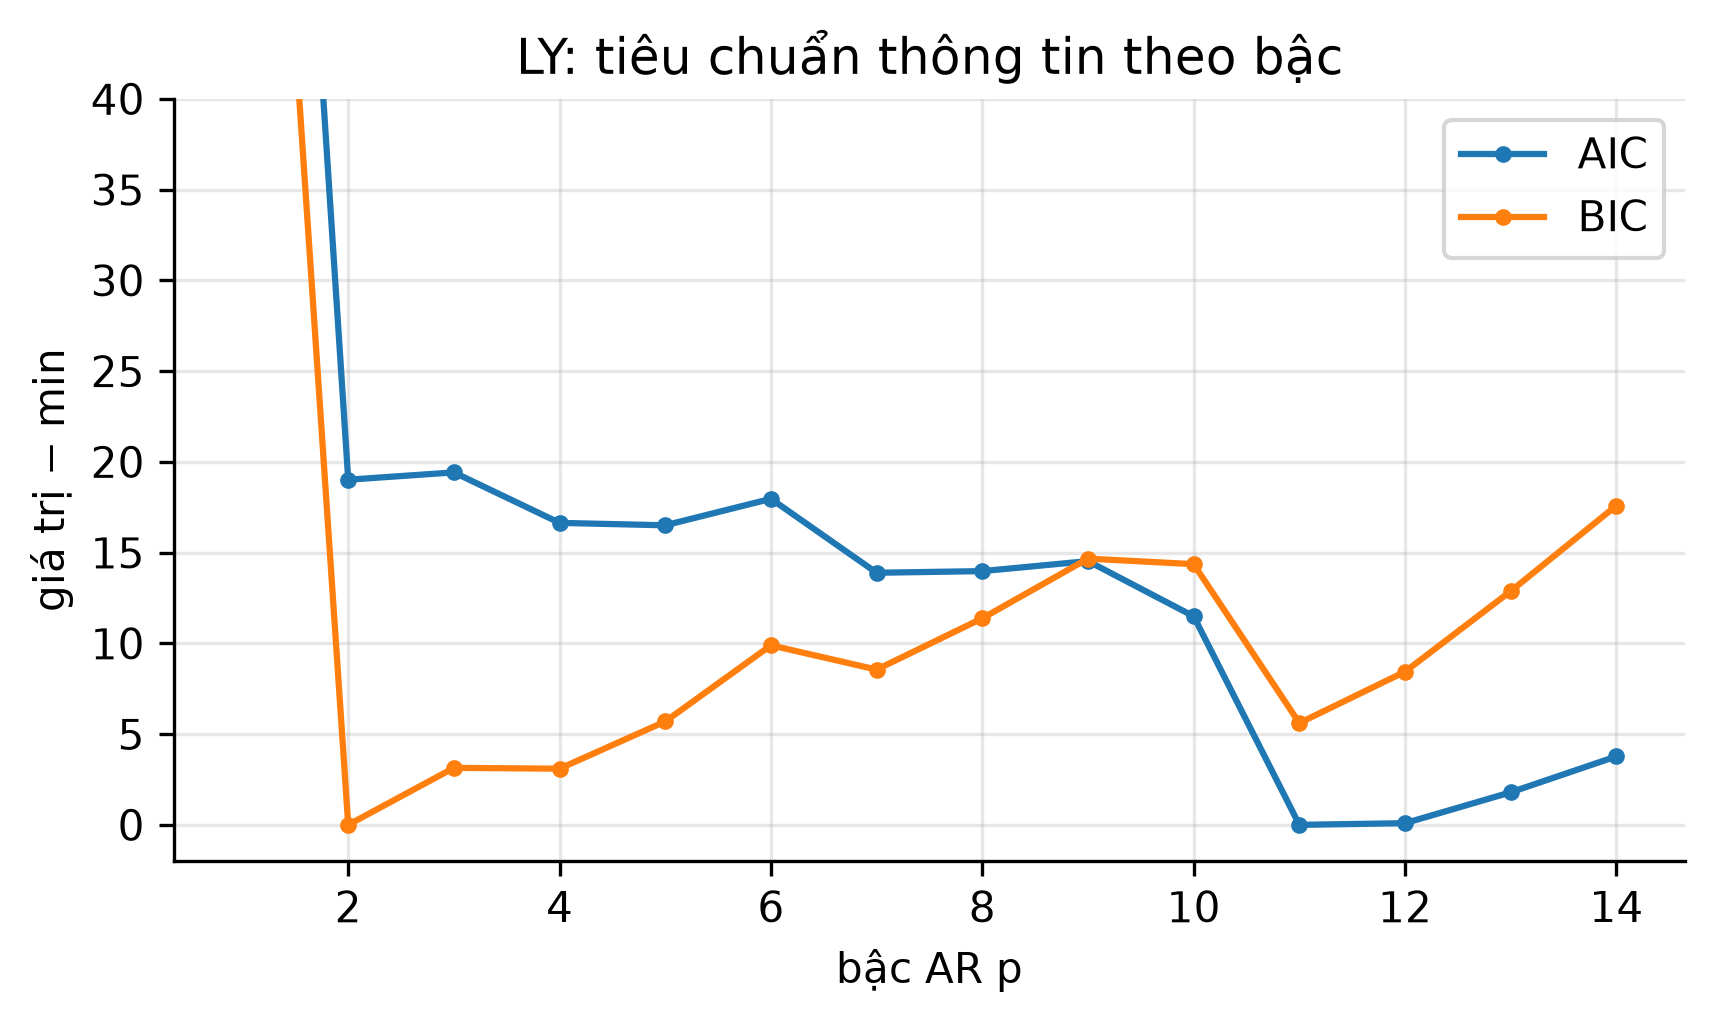

p,1,2,3,4,5,6,7,8,9,10,11,12,13,14
AIC,84.11,-5.01,-4.61,-7.39,-7.52,-6.06,-10.14,-10.05,-9.49,-12.54,-24.03,-23.93,-22.23,-20.25
BIC,92.32,5.94,9.07,9.03,11.63,15.83,14.49,17.32,20.60,20.30,11.54,14.37,18.81,23.53


,k,AIC,BIC,Q_LB(10),p-value
sai số u_t,,,,,
AR(1),4,218.450147,228.790017,12.259840,0.199054
AR(2),5,212.396535,225.321372,3.945013,0.862050
AR(3),6,214.006865,229.516670,3.356189,0.850215
MA(1),4,237.172596,247.512466,32.487714,0.000164
MA(2),5,219.751513,232.676350,10.816038,0.212342
"ARMA(1,1)",5,212.395380,225.320218,3.775213,0.876814


"(p,q)","(0,0)","(0,1)","(0,2)","(1,0)","(1,1)","(1,2)","(2,0)","(2,1)","(2,2)"
AIC,5388.81,5390.81,5391.48,5390.81,5391.76,5392.76,5391.48,5392.76,5394.75
BIC,5399.87,5407.40,5413.59,5407.40,5413.87,5420.39,5413.59,5420.40,5427.91


,số gốc,RMSE 1 bước,MAE 1 bước
mô hình,,,
AR(2),20,0.233926,0.188520
AR(11),20,0.203341,0.151730
trung bình quá khứ,20,0.543645,0.462881


In [34]:
show_figure(fig_path)
display(tab_ly.T.round(2))
display(tab_hu)
display(tab_dr.T.round(2))
tab_ro

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- AIC và BIC chọn bậc khác nhau ở LY: vì sao (phạt $2k$ so với $k\log n$)? Hai điểm trũng của BIC ở $p=2$ và $p=11$ ứng với cấu trúc nào?
- HU: AR(2) và ARMA(1,1) hầu như ngang nhau; nên chọn theo tiêu chí nào (đơn giản, PACF, diễn giải)?
- Thẩm định cuốn chiếu có cùng thứ hạng AR(2) so với AR(11) như AIC/BIC không?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## 11.14 Chẩn đoán phần dư và checklist báo cáo ARMA

*Bộ dữ liệu:* HU, LY, DR (cả 3)

### Nội dung lý thuyết

Phần dư $\hat\varepsilon_t$ của mô hình tốt trông như nhiễu trắng: đồ thị, ACF, $Q_{LB}(H)$ so với $\chi^2_{H-p-q}$ (tham số ARMA ước lượng làm mất $p+q$ bậc tự do),
và ACF của $\hat\varepsilon_t^2$ (cụm biến động). **Checklist:** (1) vẽ đồ thị → (2) làm dừng → (3) ACF/PACF chọn ứng viên → (4) khớp ML, nhân quả/khả nghịch, AIC/BIC → (5) phần dư trắng? Nếu không, hiệu chỉnh.
Báo cáo: biến đổi đã làm, mô hình + SE + $\hat\sigma^2$ + nghiệm, cách chọn bậc, chẩn đoán phần dư, SE có xét phụ thuộc.

### Cách triển khai

**[D]** Áp checklist cho: HU (xu thế tuyến tính + sai số AR(2), $H=10$), LY (AR(2) và AR(11), $H=20$), DR (mô hình chỉ có trung bình ⇒ phần dư $=r_t-\bar r$, $H=10$). Mỗi mô hình:
$k$, AIC, BIC, nghiệm AR, $Q_{LB}$ của phần dư (df $=H-p-q$) và của phần dư bình phương; vẽ ACF phần dư và ACF phần dư bình phương. Các bước 1–3 đã thực hiện ở 11.1, 11.11, 11.13.

### Mã lệnh Python

In [35]:
spec = [("HU", "AR(2) + xu thế", (2, 0, 0), 10), ("LY", "AR(2)", (2, 0, 0), 20), ("LY", "AR(11)", (11, 0, 0), 20), ("DR", "chỉ trung bình", (0, 0, 0), 10)]
rows = []; fig, axes = plt.subplots(len(spec), 2, figsize=(11, 10))
for i, (c, name, o, H) in enumerate(spec):
    res = fit_arma(c, o); e = np.asarray(res.resid); df = o[0] + o[2]
    q, p = A.ljung_box_manual(e, H, df); q_lib, p_lib = lb(e, H, df)
    q2, p2 = A.ljung_box_manual(e ** 2, H, 0)
    chk = R.causal_invertible_check(res.arparams, res.maparams)
    rows.append({"bộ": c, "mô hình": name, "k": len(res.params), "AIC": res.aic, "BIC": res.bic, "σ̂²": sig2(res),
                 "min|z| AR": chk["min_ar_modulus"], "nhân quả": chk["causal"], "H": H, "df": H - df,
                 "Q_LB phần dư": q, "p": p, "|tay − thư viện|": abs(q - q_lib), "Q_LB phần dư²": q2, "p (phần dư²)": p2})
    acf_bars(axes[i, 0], A.sample_acf(e, 20), len(e), f"{c} {name}: ACF phần dư")
    acf_bars(axes[i, 1], A.sample_acf(e ** 2, 20), len(e), f"{c} {name}: ACF phần dư²")
fig.tight_layout(); fig_path = save_figure(fig, "bai11_11_14_residual_acf")
tab = save_table(pd.DataFrame(rows).set_index(["bộ", "mô hình"]), "bai11_11_14_residual_diagnostics")
ols = sm.OLS(Y["HU"], sm.add_constant(X_HU)).fit(); ar2 = fit_arma("HU", (2, 0, 0), cov_type="oim")
print(f"HU hệ số dốc: OLS {ols.params[1]:.4f} (SE {ols.bse[1]:.4f}) so với ML sai số AR(2) {ar2.params[1]:.4f} (SE {ar2.bse[1]:.4f})")

HU hệ số dốc: OLS -0.0242 (SE 0.0040) so với ML sai số AR(2) -0.0216 (SE 0.0081)


### Kết quả

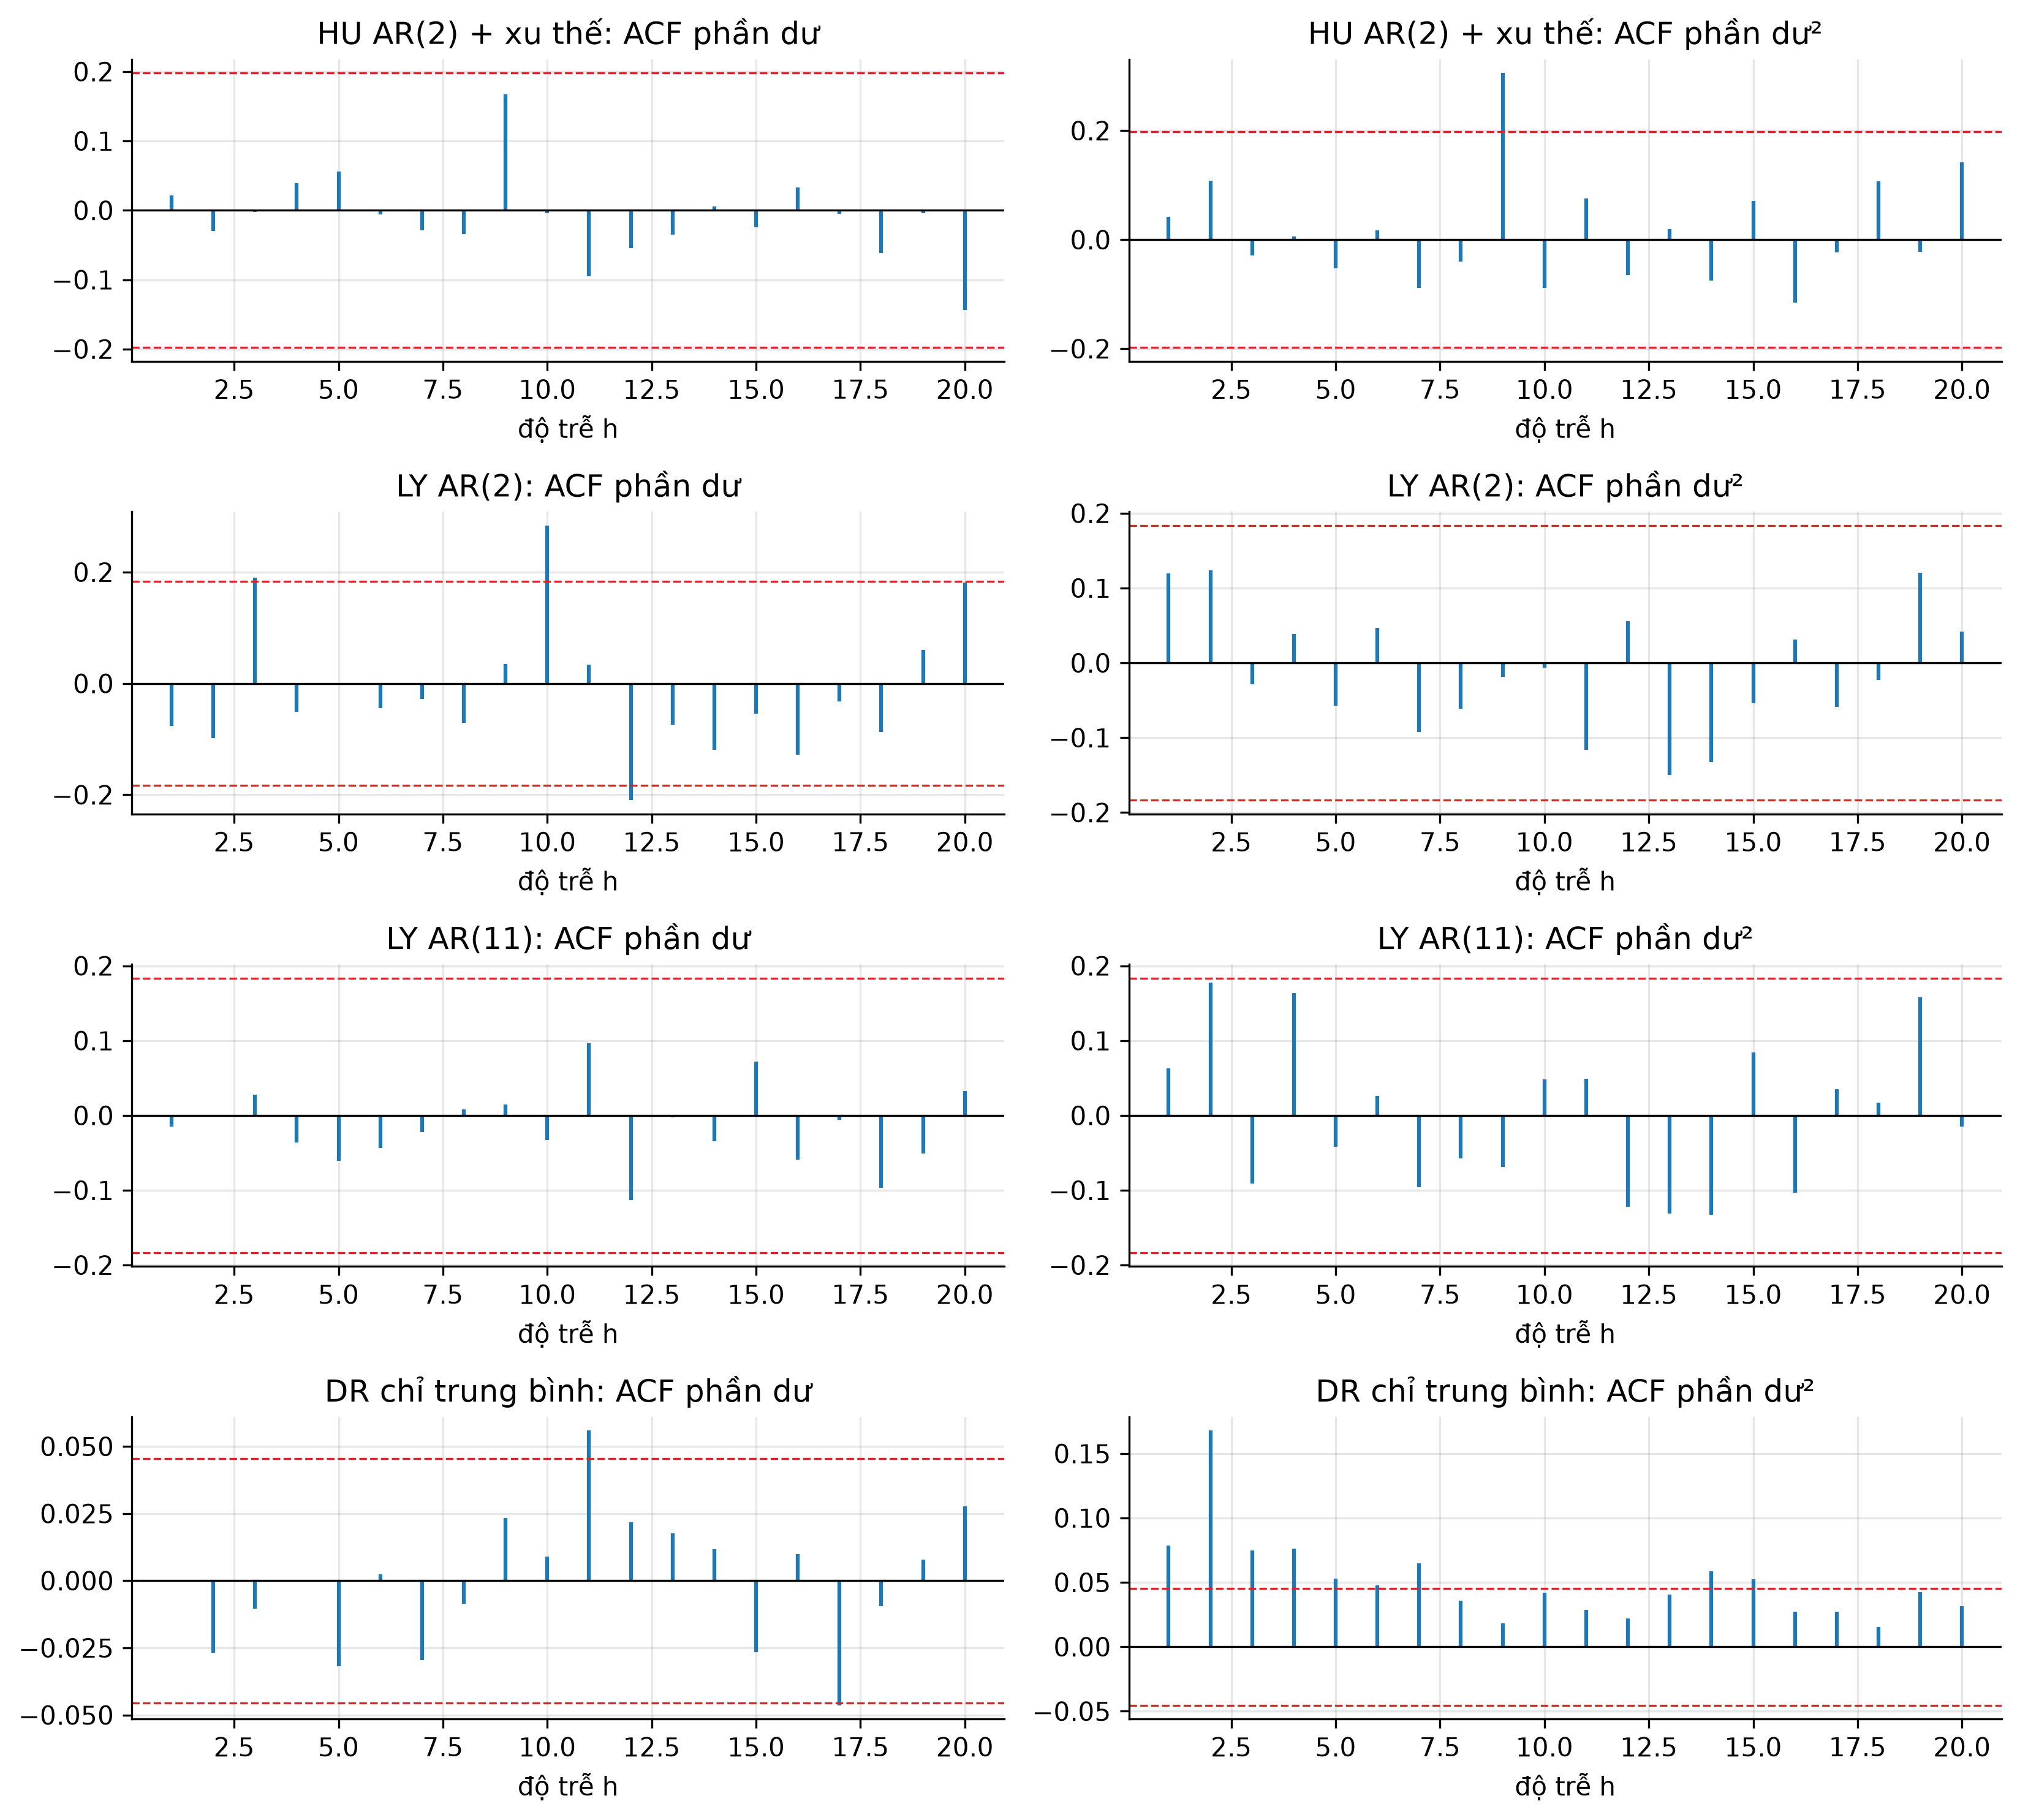

bộ                           HU         LY                        DR
mô hình          AR(2) + xu thế      AR(2)     AR(11) chỉ trung bình
k                             5          4         13              2
AIC                  212.396535  -5.009319 -24.025613      5388.8148
BIC                  225.321372   5.935475  11.544967    5399.870388
σ̂²                    0.456611   0.051069   0.036111       1.060491
min|z| AR              1.852803   1.162579     1.0155            NaN
nhân quả                   True       True       True           True
H                            10         20         20             10
df                            8         18          9             10
Q_LB phần dư           3.945013  35.182153   7.179302       6.365577
p                       0.86205   0.008966   0.618458       0.783671
|tay − thư viện|            0.0        0.0        0.0            0.0
Q_LB phần dư²         13.967414  16.738759   24.05117      108.71108
p (phần dư²)           0.174483   0.669866   0.240164            0.0

In [36]:
show_figure(fig_path)
tab.T

### Phân tích và diễn giải

**TODO(nhóm):** viết 2–4 câu diễn giải kết quả ở trên, liên hệ trực tiếp với lý thuyết. Câu hỏi gợi ý:

- Phần dư HU, LY có còn tự tương quan không ($p$ của $Q_{LB}$)? AR(2) và AR(11) của LY khác nhau thế nào (so với giá trị bài giảng 0.009 và 0.52)?
- DR: phần dư trắng nhưng bình phương thì sao? Đây là dấu hiệu của hiện tượng gì và vì sao ARMA không đủ (chỉ nhắc GARCH như giới hạn, không khớp)?
- Báo cáo ARMA của nhóm đã đủ các ý của checklist chưa (đặc biệt SE có xét phụ thuộc của hệ số dốc)?

### Nhận xét

**TODO(nhóm):** kết quả có phù hợp lý thuyết không? Nếu lệch, do đặc điểm nào của dữ liệu?

## Bảng tổng hợp: ID × bộ dữ liệu → phù hợp lý thuyết?

Nguyên liệu cho Mục 4.6 của báo cáo (Bài 11). Điền cột cuối sau khi viết xong các nhận xét.

| ID | Nội dung | Bộ | Phù hợp lý thuyết? |
|---|---|---|---|
| 11.1 | Chuỗi thời gian, dừng và nhiễu trắng | HU, LY, DR (cả 3) | **TODO(nhóm)** |
| 11.2 | Tính chất của hàm tự hiệp phương sai | HU, LY, DR (cả 3) | **TODO(nhóm)** |
| 11.3 | Trung bình mẫu khi có phụ thuộc | HU (chính), LY, DR; mô phỏng AR(1) | **TODO(nhóm)** |
| 11.4 | ACF mẫu, dải iid, Bartlett và kiểm định Ljung–Box | HU, LY, DR (cả 3) + mô phỏng nhiễu iid | **TODO(nhóm)** |
| 11.5 | Quá trình tuyến tính, toán tử lùi, trọng số ψ và ACF lý thuyết | HU, LY (DR: giải thích không áp dụng) | **TODO(nhóm)** |
| 11.6 | Mô hình AR(1) | HU (chính); LY, DR: giải thích | **TODO(nhóm)** |
| 11.7 | AR(p): tính nhân quả và phương trình Yule–Walker | LY, HU (DR: không áp dụng) | **TODO(nhóm)** |
| 11.8 | AR(2): tam giác nhân quả và chu kỳ | LY (chính), HU; DR: không áp dụng | **TODO(nhóm)** |
| 11.9 | Mô hình MA(q): ACF cắt cụt, MA(1), khả nghịch | DR, HU (LY: giải thích) + mô phỏng MA(2) | **TODO(nhóm)** |
| 11.10 | ARMA(p, q): nhân quả, khả nghịch, nghiệm chung | HU, LY (DR: minh họa thừa tham số) | **TODO(nhóm)** |
| 11.11 | Tự tương quan riêng phần (PACF) | HU (đã khử xu thế), LY, DR (cả 3) | **TODO(nhóm)** |
| 11.12 | Ước lượng: Yule–Walker, OLS, cực đại hợp lý | LY, HU (+ mô phỏng AR(2)); DR: không áp dụng | **TODO(nhóm)** |
| 11.13 | Chọn bậc bằng AIC/BIC và thẩm định cuốn chiếu | LY, HU (DR: lưới ARMA nhỏ) | **TODO(nhóm)** |
| 11.14 | Chẩn đoán phần dư và checklist báo cáo ARMA | HU, LY, DR (cả 3) | **TODO(nhóm)** |